<a href="https://colab.research.google.com/github/deeptipatro2005-dev/IIITB/blob/EDA/EDA_Assg_NYC_Taxi_Analysis_Deepti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **New York City Yellow Taxi Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [1]:
import warnings
warnings.filterplus = "ignore" # Standard practice to ignore non-critical warnings during EDA

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setting up the visualization style
%matplotlib inline
sns.set(style="whitegrid")

In [3]:
# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.1.3
pandas version: 2.2.3
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [8]:
# Try loading one file

df = pd.read_parquet('/content/yellow_tripdata_2023-01.parquet')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3066766 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee           

#### **Sampling the Data**

One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```python
# sample 0.05 of the hour_data
sample = hour_data.sample(frac = 0.05, random_state = 42)

# adding data for this hour to the combined DF
sampled_data = pd.concat([sampled_data, sample])
```

This `sampled_data` will contain 5% values selected at random from each hour. Keep in mind that you sample by date AND hour to maintain the temporal distribution of the original dataset.

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

It is recommended to not load all the files at once to avoid memory overload. We will iterate through each month, sample 5% of the data per hour, and concatenate them.

In [9]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload
df.sample(frac=0.05, random_state=42)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
2790731,2,2023-01-29 17:52:02,2023-01-29 17:56:43,1.0,1.17,1.0,N,262,74,2,7.2,0.0,0.5,0.00,0.0,1.0,11.20,2.5,0.0
666153,1,2023-01-08 15:57:24,2023-01-08 16:02:47,1.0,0.90,1.0,N,229,237,2,6.5,2.5,0.5,0.00,0.0,1.0,10.50,2.5,0.0
1985683,2,2023-01-21 19:38:01,2023-01-21 19:45:02,1.0,0.95,1.0,N,45,261,1,7.9,0.0,0.5,2.38,0.0,1.0,14.28,2.5,0.0
2154231,2,2023-01-23 16:07:31,2023-01-23 16:26:46,5.0,0.88,1.0,N,237,141,1,16.3,2.5,0.5,1.50,0.0,1.0,24.30,2.5,0.0
2493619,2,2023-01-26 21:21:08,2023-01-26 21:24:48,2.0,1.03,1.0,N,229,140,1,6.5,1.0,0.5,2.30,0.0,1.0,13.80,2.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2808515,1,2023-01-29 21:36:59,2023-01-29 21:53:10,1.0,4.80,1.0,N,48,13,2,22.6,3.5,0.5,0.00,0.0,1.0,27.60,2.5,0.0
777146,2,2023-01-09 21:08:13,2023-01-09 21:12:57,1.0,0.98,1.0,N,161,237,1,7.2,1.0,0.5,1.50,0.0,1.0,13.70,2.5,0.0
2651154,2,2023-01-28 11:05:54,2023-01-28 11:07:56,1.0,0.24,1.0,N,236,236,1,4.4,0.0,0.5,2.52,0.0,1.0,10.92,2.5,0.0
2837468,2,2023-01-30 11:48:19,2023-01-30 11:54:27,1.0,1.20,1.0,N,264,264,2,8.6,0.0,0.5,0.00,0.0,1.0,12.60,2.5,0.0


## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

In [10]:
# Save the combined sampled dataset for future use to avoid re-running the loop
df.to_parquet('nyc_taxi_sampled_2023.parquet')
print("Sampled data saved to 'nyc_taxi_sampled_2023.parquet'")

Sampled data saved to 'nyc_taxi_sampled_2023.parquet'


In [23]:
import pandas as pd
import os

# List of files to process
#file_list = [f'/content/yellow_tripdata_2023-{i}.parquet' for i in range(1, 13)]
# Fixed: added :02d so months 1-9 format as '01', '02', ..., '09'
file_list = [f'/content/yellow_tripdata_2023-{i:02d}.parquet' for i in range(1, 13)]
# Main dataframe to store all sampled data
df = pd.DataFrame()

for file_path in file_list:
    try:
        if os.path.exists(file_path):
            print(f"Processing and sampling: {file_path}")
            # Load monthly data
            month_df = pd.read_parquet(file_path)

            # Ensure pickup time is datetime and extract sampling keys
            month_df['tpep_pickup_datetime'] = pd.to_datetime(month_df['tpep_pickup_datetime'])
            month_df['pickup_date'] = month_df['tpep_pickup_datetime'].dt.date
            month_df['pickup_hour'] = month_df['tpep_pickup_datetime'].dt.hour

            # Stratified sampling: 5% per hour of each day
            sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(
                lambda x: x.sample(frac=0.05, random_state=42) if not x.empty else x
            ).reset_index(drop=True)

            # Combine into master dataframe
            df = pd.concat([df, sampled_month], ignore_index=True)
        else:
            print(f"Warning: {file_path} not found.")
    except Exception as e:
        print(f"Error processing {file_path}: {e}")

print(f"\nProcess complete. Final dataset contains {len(df)} rows.")

Processing and sampling: /content/yellow_tripdata_2023-01.parquet


/tmp/ipykernel_896/2188586618.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(


Processing and sampling: /content/yellow_tripdata_2023-02.parquet


/tmp/ipykernel_896/2188586618.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(


Processing and sampling: /content/yellow_tripdata_2023-03.parquet


/tmp/ipykernel_896/2188586618.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(


... (15 outputs left out)

/tmp/ipykernel_896/2188586618.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(


Processing and sampling: /content/yellow_tripdata_2023-12.parquet


/tmp/ipykernel_896/2188586618.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_month = month_df.groupby(['pickup_date', 'pickup_hour']).apply(



Process complete. Final dataset contains 1915511 rows.


In [24]:
# Save the combined master DataFrame 'df' as a CSV file
df.to_csv('/content/nyc_taxi_sampled_2023.csv', index=False)
print("Master dataset saved as CSV.")
print("Shape:", df.shape)

Master dataset saved as CSV.
Shape: (1915511, 22)


In [25]:
# Downsample the master dataset to exactly 30,000 rows
if len(df) > 30000:
    df = df.sample(n=30000, random_state=42).reset_index(drop=True)

# Save the 30,000-row sampled dataset
df.to_parquet('/content/nyc_taxi_sampled_2023.parquet', index=False)
df.to_csv('/content/nyc_taxi_sampled_2023.csv', index=False)

print("Sampled dataset updated successfully.")
print("New Shape:", df.shape)

Sampled dataset updated successfully.
New Shape: (30000, 22)


Now we can load the new data directly.

In [49]:
# Load the new data file
# Load the 30,000-row sampled dataset
df = pd.read_parquet('/content/nyc_taxi_sampled_2023.parquet')



In [50]:
# df.head()
# Verify dataset shape and columns
print("Loaded DataFrame shape:", df.shape)
df.head()

Loaded DataFrame shape: (30000, 22)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour,Airport_fee
0,2,2023-11-03 17:49:43,2023-11-03 18:01:34,1.0,1.89,1.0,N,141,239,1,...,0.5,3.86,0.00,1.0,23.16,2.5,NaN,2023-11-03,17,0.0
1,2,2023-09-01 05:56:35,2023-09-01 06:27:49,2.0,17.01,3.0,N,88,1,2,...,0.0,0.00,20.75,1.0,107.35,0.0,NaN,2023-09-01,5,0.0
2,2,2023-02-07 14:47:55,2023-02-07 14:57:34,2.0,1.81,1.0,N,142,43,1,...,0.5,3.22,0.00,1.0,19.32,2.5,NaN,2023-02-07,14,0.0
3,2,2023-12-18 18:48:36,2023-12-18 19:10:36,1.0,2.79,1.0,N,163,151,2,...,0.5,0.00,0.00,1.0,23.50,2.5,NaN,2023-12-18,18,0.0
4,2,2023-12-09 07:37:07,2023-12-09 07:41:58,1.0,1.23,1.0,N,229,137,1,...,0.5,1.00,0.00,1.0,12.90,2.5,NaN,2023-12-09,7,0.0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   VendorID               30000 non-null  int64         
 1   tpep_pickup_datetime   30000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  30000 non-null  datetime64[us]
 3   passenger_count        29012 non-null  float64       
 4   trip_distance          30000 non-null  float64       
 5   RatecodeID             29012 non-null  float64       
 6   store_and_fwd_flag     29012 non-null  object        
 7   PULocationID           30000 non-null  int64         
 8   DOLocationID           30000 non-null  int64         
 9   payment_type           30000 non-null  int64         
 10  fare_amount            30000 non-null  float64       
 11  extra                  30000 non-null  float64       
 12  mta_tax                30000 non-null  float64       
 13  t

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [53]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)
df.drop(columns=['store_and_fwd_flag'], errors='ignore', inplace=True)


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   VendorID               30000 non-null  int64         
 1   tpep_pickup_datetime   30000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  30000 non-null  datetime64[us]
 3   passenger_count        29012 non-null  float64       
 4   trip_distance          30000 non-null  float64       
 5   RatecodeID             29012 non-null  float64       
 6   PULocationID           30000 non-null  int64         
 7   DOLocationID           30000 non-null  int64         
 8   payment_type           30000 non-null  int64         
 9   fare_amount            30000 non-null  float64       
 10  extra                  30000 non-null  float64       
 11  mta_tax                30000 non-null  float64       
 12  tip_amount             30000 non-null  float64       
 13  t

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [56]:
# Combine the two airport fee columns

print(df[['airport_fee', 'Airport_fee']].info())

print("\nMissing values:")
print(df[['airport_fee', 'Airport_fee']].isnull().sum())

print("\nFirst 10 rows:")
print(df[['airport_fee', 'Airport_fee']].head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   airport_fee  2289 non-null   float64
 1   Airport_fee  26723 non-null  float64
dtypes: float64(2)
memory usage: 468.9 KB
None

Missing values:
airport_fee    27711
Airport_fee     3277
dtype: int64

First 10 rows:
   airport_fee  Airport_fee
0          NaN         0.00
1          NaN         0.00
2          NaN         0.00
3          NaN         0.00
4          NaN         0.00
5          NaN         0.00
6          NaN         0.00
7          NaN         0.00
8          NaN         1.25
9          NaN         0.00


In [57]:
# Check rows where both columns have values
both_present = df[['airport_fee', 'Airport_fee']].dropna()

print("Rows where both have values:", len(both_present))
print("Different values:",
      (both_present['airport_fee'] != both_present['Airport_fee']).sum())

Rows where both have values: 0
Different values: 0


In [58]:
df['airport_fee'] = df['airport_fee'].fillna(df['Airport_fee'])
df.drop(columns=['Airport_fee'], inplace=True)
df['airport_fee'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 30000 entries, 0 to 29999
Series name: airport_fee
Non-Null Count  Dtype  
--------------  -----  
29012 non-null  float64
dtypes: float64(1)
memory usage: 234.5 KB


In [84]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID',
       'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax',
       'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount',
       'congestion_surcharge', 'airport_fee', 'pickup_date', 'pickup_hour'],
      dtype='object')

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [73]:
# check where values of fare amount are negative
negative_fare = df[df['fare_amount'] < 0]

print("Number of negative fare_amount records:", len(negative_fare))

negative_fare[
    ['RatecodeID', 'fare_amount', 'total_amount']
]


Number of negative fare_amount records: 315


,RatecodeID,fare_amount,total_amount
10,1.0,-3.7,-7.70
142,1.0,-17.7,-21.70
143,1.0,-16.3,-20.30
367,1.0,-19.1,-25.60
380,1.0,-36.6,-39.85
...,...,...,...
29128,1.0,-5.1,-9.10
29327,1.0,-21.9,-25.90
29347,1.0,-21.2,-19.65
29435,1.0,-4.4,-9.40


In [74]:
monetary_columns = [
    'fare_amount',
    'extra',
    'mta_tax',
    'tip_amount',
    'tolls_amount',
    'improvement_surcharge',
    'total_amount',
    'congestion_surcharge',
    'airport_fee'
]
negative_counts = (df[monetary_columns] < 0).sum()

print("Negative values by column:")
print(negative_counts)
print(
    negative_counts[negative_counts > 0]
)

Negative values by column:
fare_amount              315
extra                    170
mta_tax                  306
tip_amount                 1
tolls_amount              14
improvement_surcharge    313
total_amount             313
congestion_surcharge     254
airport_fee               31
dtype: int64
fare_amount              315
extra                    170
mta_tax                  306
tip_amount                 1
tolls_amount              14
improvement_surcharge    313
total_amount             313
congestion_surcharge     254
airport_fee               31
dtype: int64


Did you notice something different in the `RatecodeID` column for above records?

In [76]:
# Analyse RatecodeID for the negative fare amounts

print("RatecodeID distribution for negative fare records:")

print(
    negative_fare['RatecodeID'].value_counts(dropna=False)
)

RatecodeID distribution for negative fare records:
RatecodeID
1.0    283
2.0     22
3.0      6
NaN      3
5.0      1
Name: count, dtype: int64


In [79]:
negative_fare

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
10,2,2023-02-01 10:50:17,2023-02-01 10:52:03,1.0,0.18,1.0,90,186,4,-3.7,0.0,-0.5,0.00,0.0,-1.0,-7.70,-2.5,0.00,2023-02-01,10
142,2,2023-07-02 14:19:23,2023-07-02 14:37:13,1.0,2.62,1.0,234,261,2,-17.7,0.0,-0.5,0.00,0.0,-1.0,-21.70,-2.5,0.00,2023-07-02,14
143,2,2023-01-10 15:41:56,2023-01-10 16:00:40,1.0,1.20,1.0,262,140,4,-16.3,0.0,-0.5,0.00,0.0,-1.0,-20.30,-2.5,0.00,2023-01-10,15
367,2,2023-06-26 18:59:13,2023-06-26 19:17:57,1.0,3.25,1.0,48,144,2,-19.1,-2.5,-0.5,0.00,0.0,-1.0,-25.60,-2.5,0.00,2023-06-26,18
380,2,2023-11-10 18:49:41,2023-11-10 19:19:46,1.0,8.17,1.0,132,77,4,-36.6,0.0,-0.5,0.00,0.0,-1.0,-39.85,0.0,-1.75,2023-11-10,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29128,2,2023-06-10 17:59:37,2023-06-10 18:02:18,2.0,0.65,1.0,236,236,4,-5.1,0.0,-0.5,0.00,0.0,-1.0,-9.10,-2.5,0.00,2023-06-10,17
29327,2,2023-11-08 14:34:31,2023-11-08 14:59:52,1.0,1.84,1.0,234,48,4,-21.9,0.0,-0.5,0.00,0.0,-1.0,-25.90,-2.5,0.00,2023-11-08,14
29347,2,2023-07-15 00:35:54,2023-07-15 00:56:34,1.0,3.39,1.0,211,48,4,-21.2,-1.0,-0.5,6.55,0.0,-1.0,-19.65,-2.5,0.00,2023-07-15,0
29435,2,2023-09-03 22:47:48,2023-09-03 22:49:34,1.0,0.32,1.0,211,114,3,-4.4,-1.0,-0.5,0.00,0.0,-1.0,-9.40,-2.5,0.00,2023-09-03,22


In [80]:
# Find which columns have negative values

# Identify numerical columns that contain negative values
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
neg_summary = {col: (df[col] < 0).sum() for col in num_cols if (df[col] < 0).sum() > 0}

print("Columns with negative values and their counts:")
for col, count in neg_summary.items():
    print(f"{col}: {count} rows")

Columns with negative values and their counts:
fare_amount: 315 rows
extra: 170 rows
mta_tax: 306 rows
tip_amount: 1 rows
tolls_amount: 14 rows
improvement_surcharge: 313 rows
total_amount: 313 rows
congestion_surcharge: 254 rows
airport_fee: 31 rows


In [81]:
# fix these negative values

# Option A: Convert negative fare/surcharge amounts to positive using absolute value
fare_cols = [
    'fare_amount', 'extra', 'mta_tax', 'tip_amount',
    'tolls_amount', 'improvement_surcharge', 'total_amount',
    'congestion_surcharge', 'airport_fee'
]

for col in fare_cols:
    if col in df.columns:
        df[col] = df[col].abs()

# Re-calculate total_amount to ensure consistency across columns
df['total_amount'] = (
    df['fare_amount'] + df['extra'] + df['mta_tax'] +
    df['tip_amount'] + df['tolls_amount'] + df['improvement_surcharge'] +
    df['congestion_surcharge'].fillna(0) + df['airport_fee'].fillna(0)
)

print("Negative values successfully fixed.")
print("Remaining negative rows in fare_amount:", (df['fare_amount'] < 0).sum())

Negative values successfully fixed.
Remaining negative rows in fare_amount: 0


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [82]:
# Find the proportion of missing values in each column
missing_proportion = df.isnull().mean() * 100
print("Percentage of missing values in each column:")
print(missing_proportion)


Percentage of missing values in each column:
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          3.293333
trip_distance            0.000000
RatecodeID               3.293333
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     3.293333
airport_fee              3.293333
pickup_date              0.000000
pickup_hour              0.000000
dtype: float64


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [83]:
# Display the rows with null values

# Impute NaN values in 'passenger_count'

passenger_null = df[df['passenger_count'].isnull()]

print("Number of missing passenger_count values:",
      len(passenger_null))

Number of missing passenger_count values: 988


In [84]:
# Check initial count of zeroes in passenger_count
zero_passenger_count = (df['passenger_count'] == 0).sum()
print(f"Number of rows with passenger_count == 0: {zero_passenger_count}")

# 1. Impute missing (NaN) values with the mode (1.0)
mode_passenger_count = df['passenger_count'].mode()[0]
df['passenger_count'] = df['passenger_count'].fillna(mode_passenger_count)

# 2. Replace 0 passenger counts with 1.0 (single rider assumption)
df['passenger_count'] = df['passenger_count'].replace(0, mode_passenger_count)

# Verify no missing or 0 values remain
print("Remaining missing passenger_count values:", df['passenger_count'].isnull().sum())
print("Remaining zero passenger_count values:", (df['passenger_count'] == 0).sum())
print("\nPassenger count value distribution:")
print(df['passenger_count'].value_counts())

Number of rows with passenger_count == 0: 462
Remaining missing passenger_count values: 0
Remaining zero passenger_count values: 0

Passenger count value distribution:
passenger_count
1.0    23381
2.0     4299
3.0     1110
4.0      606
5.0      345
6.0      259
Name: count, dtype: int64


Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [87]:
# Fix missing values in 'RatecodeID'
# 1. Identify the most common RatecodeID (mode)
ratecode_mode = df['RatecodeID'].mode()[0]
print(f"Mode for RatecodeID: {ratecode_mode}")

# 2. Impute missing (NaN) values with the mode
df['RatecodeID'] = df['RatecodeID'].fillna(ratecode_mode)

# Verify no missing values remain
print("Remaining missing values in RatecodeID:", df['RatecodeID'].isnull().sum())

# Display value counts to check distribution
print("\nRatecodeID value distribution:")
print(df['RatecodeID'].value_counts())

Mode for RatecodeID: 1.0
Remaining missing values in RatecodeID: 0

RatecodeID value distribution:
RatecodeID
1.0     28410
2.0      1111
5.0       174
99.0      139
3.0       110
4.0        56
Name: count, dtype: int64


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [89]:
# handle null values in congestion_surcharge

# Check count of missing values before imputation
missing_count = df['congestion_surcharge'].isnull().sum()
print(f"Missing values before imputation: {missing_count}")

# Find the most common surcharge value (mode, which is 2.5)
congestion_mode = df['congestion_surcharge'].mode()[0]
print(f"Mode for congestion_surcharge: {congestion_mode}")

# Impute missing values with the mode
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(congestion_mode)

# Verify no missing values remain
print("Remaining missing values in congestion_surcharge:", df['congestion_surcharge'].isnull().sum())
print("\nCongestion Surcharge Value Counts:")
print(df['congestion_surcharge'].value_counts())


Missing values before imputation: 0
Mode for congestion_surcharge: 2.5
Remaining missing values in congestion_surcharge: 0

Congestion Surcharge Value Counts:
congestion_surcharge
2.5    27738
0.0     2261
1.0        1
Name: count, dtype: int64


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [91]:
# Handle any remaining missing values
# 1. Check for any remaining missing values across all columns
print("Missing values per column BEFORE cleanup:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Impute any remaining numeric columns with 0 or median as appropriate
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        # Fill missing values with 0 (standard for optional fee/surcharge columns)
        df[col] = df[col].fillna(0)

# 3. Impute any remaining categorical/object columns with mode or 'Unknown'
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')

# 4. Final verification
print("\nMissing values per column AFTER cleanup:")
print(df.isnull().sum().sum(), "total missing values remaining in the dataset.")


Missing values per column BEFORE cleanup:
Series([], dtype: int64)

Missing values per column AFTER cleanup:
0 total missing values remaining in the dataset.


### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [92]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns

# 1. Summary statistics for numerical columns
print("--- Summary Statistics ---")
display(df.describe().T)

# 2. Check for out-of-place / extreme potential outliers
print("\n--- Potential Outliers & Extreme Values Summary ---")

outlier_checks = {
    "Trip distance == 0": (df['trip_distance'] == 0).sum(),
    "Trip distance > 100 miles": (df['trip_distance'] > 100).sum(),
    "Fare amount <= 0": (df['fare_amount'] <= 0).sum(),
    "Fare amount > 300": (df['fare_amount'] > 300).sum(),
    "Zero distance but fare > 300": ((df['trip_distance'] == 0) & (df['fare_amount'] > 300)).sum(),
    "Total amount > 500": (df['total_amount'] > 500).sum(),
    "Passenger count > 6": (df['passenger_count'] > 6).sum(),
    "Tip amount > 100": (df['tip_amount'] > 100).sum(),
}

for check, count in outlier_checks.items():
    print(f"{check}: {count} rows")

--- Summary Statistics ---


,count,mean,min,25%,50%,75%,max,std
VendorID,30000.0,1.736867,1.0,1.0,2.0,2.0,6.0,0.44486
tpep_pickup_datetime,30000,2023-07-03 10:32:56.274833,2023-01-01 00:13:24,2023-04-04 12:54:05,2023-06-27 18:15:47,2023-10-07 00:09:50.500000,2023-12-31 23:48:53,NaN
tpep_dropoff_datetime,30000,2023-07-03 10:50:14.869233,2023-01-01 00:28:44,2023-04-04 13:05:52.500000,2023-06-27 18:21:57.500000,2023-10-07 00:23:42,2023-12-31 23:52:27,NaN
passenger_count,30000.0,1.367067,1.0,1.0,1.0,1.0,6.0,0.859197
trip_distance,30000.0,4.50549,0.0,1.03,1.78,3.4,18797.78,134.174815
RatecodeID,30000.0,1.527233,1.0,1.0,1.0,1.0,99.0,6.662082
PULocationID,30000.0,165.622,1.0,132.0,162.0,234.0,265.0,63.874769
DOLocationID,30000.0,164.274133,1.0,114.0,162.0,234.0,265.0,69.768572
payment_type,30000.0,1.188167,0.0,1.0,1.0,1.0,4.0,0.564302
fare_amount,30000.0,19.826273,0.0,9.3,13.5,21.9,475.0,18.322863



--- Potential Outliers & Extreme Values Summary ---
Trip distance == 0: 624 rows
Trip distance > 100 miles: 3 rows
Fare amount <= 0: 8 rows
Fare amount > 300: 1 rows
Zero distance but fare > 300: 0 rows
Total amount > 500: 0 rows
Passenger count > 6: 0 rows
Tip amount > 100: 1 rows


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [93]:
# remove passenger_count > 6
# Remove instances where passenger_count > 6
initial_rows = len(df)
df = df[df['passenger_count'] <= 6]
print(f"Removed {initial_rows - len(df)} rows with passenger_count > 6.")

Removed 0 rows with passenger_count > 6.


In [94]:
# Continue with outlier handling
# 1. Remove entries where trip_distance is nearly 0 and fare_amount > 300
cond_zero_dist_high_fare = (df['trip_distance'] <= 0.1) & (df['fare_amount'] > 300)

# 2. Remove entries where both trip_distance and fare_amount are 0 for different zones
cond_zero_dist_zero_fare_diff_zones = (
    (df['trip_distance'] == 0) &
    (df['fare_amount'] == 0) &
    (df['PULocationID'] != df['DOLocationID'])
)

# 3. Remove entries where trip_distance > 250 miles (extreme distance outliers)
cond_extreme_distance = df['trip_distance'] > 250

# 4. Remove entries where payment_type == 0 (invalid payment code)
cond_invalid_payment = df['payment_type'] == 0

# Combine all outlier conditions to filter them out
outlier_mask = (
    cond_zero_dist_high_fare |
    cond_zero_dist_zero_fare_diff_zones |
    cond_extreme_distance |
    cond_invalid_payment
)

print(f"Total outlier rows identified: {outlier_mask.sum()}")

# Drop outliers and reset index
df = df[~outlier_mask].reset_index(drop=True)

# Final shape check
print("Dataset shape after outlier removal:", df.shape)


Total outlier rows identified: 991
Dataset shape after outlier removal: (29009, 20)


In [95]:
# Do any columns need standardising?
# 1. Standardise Date and Datetime Data Types
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
df['pickup_date'] = pd.to_datetime(df['pickup_date'])

# 2. Convert ID/Categorical Columns from floats/ints to Categorical or Integer Types
categorical_cols = ['VendorID', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype('int64').astype('category')

# 3. Ensure Passenger Count is Integer
if 'passenger_count' in df.columns:
    df['passenger_count'] = df['passenger_count'].astype('int64')

# 4. Standardise Currency/Monetary Columns to 2 Decimal Places
float_cols = [
    'fare_amount', 'extra', 'mta_tax', 'tip_amount',
    'tolls_amount', 'improvement_surcharge', 'total_amount',
    'congestion_surcharge', 'airport_fee'
]
for col in float_cols:
    if col in df.columns:
        df[col] = df[col].round(2)

# Verify updated data types and structure
print("Data types after standardisation:")
df.info()


Data types after standardisation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29009 entries, 0 to 29008
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   VendorID               29009 non-null  category      
 1   tpep_pickup_datetime   29009 non-null  datetime64[us]
 2   tpep_dropoff_datetime  29009 non-null  datetime64[us]
 3   passenger_count        29009 non-null  int64         
 4   trip_distance          29009 non-null  float64       
 5   RatecodeID             29009 non-null  category      
 6   PULocationID           29009 non-null  category      
 7   DOLocationID           29009 non-null  category      
 8   payment_type           29009 non-null  category      
 9   fare_amount            29009 non-null  float64       
 10  extra                  29009 non-null  float64       
 11  mta_tax                29009 non-null  float64       
 12  tip_amount             290

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [98]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'pickup_date',
 'pickup_hour']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

In [100]:
# 1. Feature Engineering for Temporal Features (if not already done)
df['trip_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0
df['day_of_week'] = df['tpep_pickup_datetime'].dt.day_name()
df['month'] = df['tpep_pickup_datetime'].dt.month_name()

/tmp/ipykernel_896/2243151658.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hourly_counts.index, y=hourly_counts.values, palette='viridis')


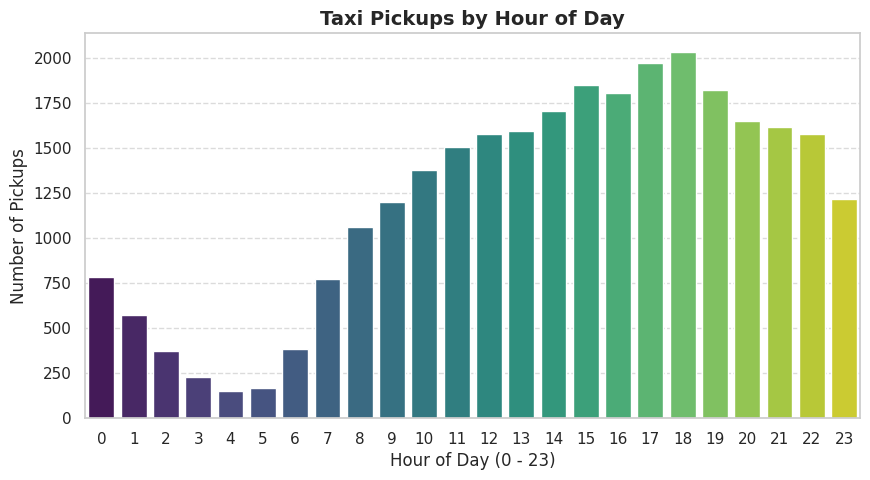

In [101]:
# Find and show the hourly trends in taxi pickups

plt.figure(figsize=(10, 5))
hourly_counts = df['pickup_hour'].value_counts().sort_index()

sns.barplot(x=hourly_counts.index, y=hourly_counts.values, palette='viridis')
plt.title('Taxi Pickups by Hour of Day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Number of Pickups', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_896/2603110279.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='day_of_week', order=day_order, palette='mako')


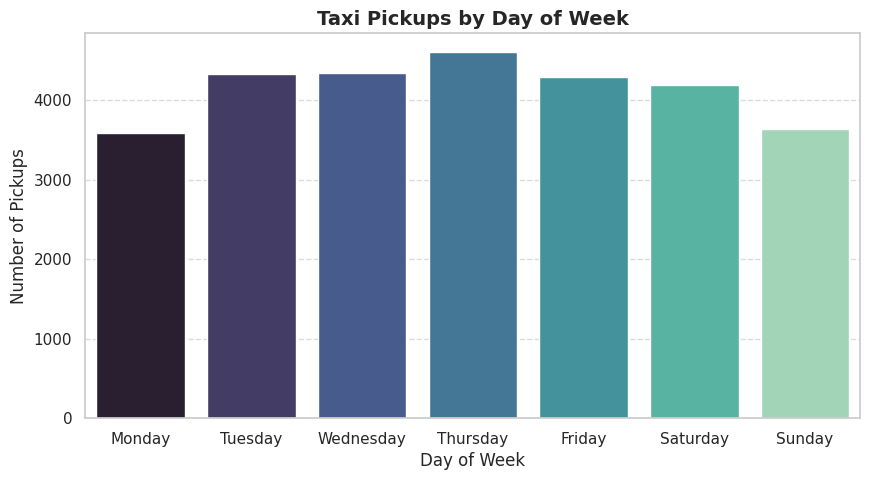

In [102]:
# Find and show the daily trends in taxi pickups (days of the week)
# Order days chronologically
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='day_of_week', order=day_order, palette='mako')
plt.title('Taxi Pickups by Day of Week', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Number of Pickups', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


/tmp/ipykernel_896/2032647225.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='month', order=month_order, palette='magma')


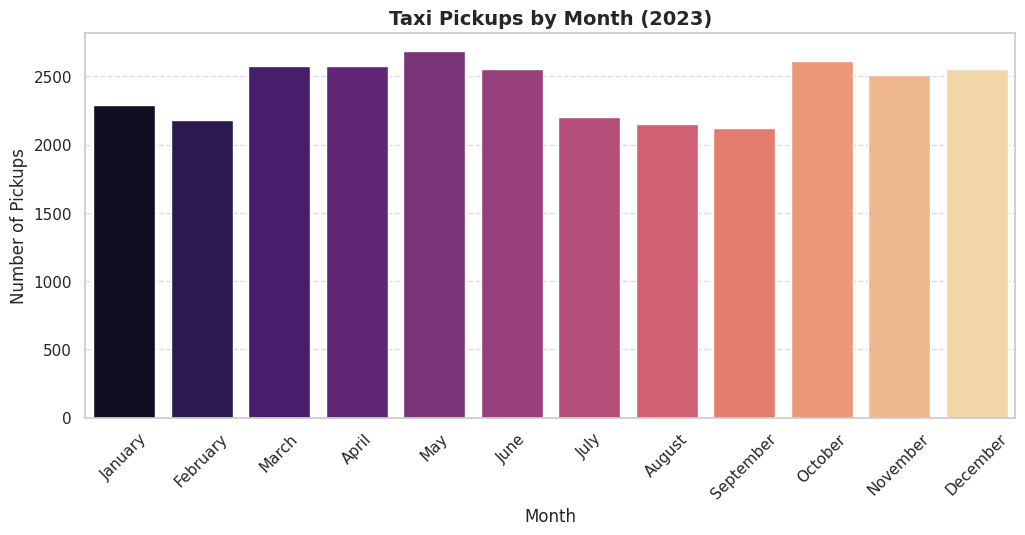

In [103]:
# Show the monthly trends in pickups
# Order months chronologically
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='month', order=month_order, palette='magma')
plt.title('Taxi Pickups by Month (2023)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Pickups', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [105]:
# Analyse the above parameters
cols = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

# Summary Statistics
print("--- Summary Statistics ---")
display(df[cols].describe().T)

# Check for zero values
print("\n--- Zero Value Counts ---")
for col in cols:
    zero_count = (df[col] == 0).sum()
    pct = (zero_count / len(df)) * 100
    print(f"{col} == 0: {zero_count} rows ({pct:.2f}%)")


--- Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
fare_amount,29009.0,19.732080,18.433170,0.0,9.30,13.50,21.90,475.00
tip_amount,29009.0,3.550951,4.050530,0.0,1.00,2.85,4.42,112.35
total_amount,29009.0,29.480549,23.071513,0.0,16.44,21.70,31.40,478.51
trip_distance,29009.0,3.423183,4.509752,0.0,1.04,1.76,3.34,102.90



--- Zero Value Counts ---
fare_amount == 0: 5 rows (0.02%)
tip_amount == 0: 6658 rows (22.95%)
total_amount == 0: 1 rows (0.00%)
trip_distance == 0: 409 rows (1.41%)


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?
Ans. Yes, creating a copy DataFrame without zero values is beneficial.

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?
ANS: Yes, it is suitable to drop zero-distance cases when creating a dataset for financial and trip performance analysis.Reasoning:Metric Integrity: Zero-distance records skew crucial performance metrics such as average fare per mile, average trip speed ($\text{distance}/\text{time} = 0$), and driver yield.Trip Intent: A taxi's core service is point-to-point transportation. Zero-distance trips—even within the same zone—typically represent canceled rides, driver log/meter errors, or passenger immediate drop-offs rather than standard completed transit.Best Practice: Filtering zero-distance records into a separate dataset (df_non_zero) allows for clean statistical analysis of active, moving trips while keeping the original df intact for overall trip volume auditing.



In [106]:
# Select the financial and distance columns
cols = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

# Filter out zero values across the specified columns
# Creates a copy containing only valid, positive non-zero entries
df_non_zero = df[
    (df['fare_amount'] > 0) &
    (df['total_amount'] > 0) &
    (df['trip_distance'] > 0)
].copy()

# Summary comparison
print(f"Original dataset rows: {len(df)}")
print(f"Filtered dataset rows: {len(df_non_zero)}")
print(f"Removed zero-value rows: {len(df) - len(df_non_zero)}")

Original dataset rows: 29009
Filtered dataset rows: 28596
Removed zero-value rows: 413


In [108]:
# Create a df with non zero entries for the selected parameters.
# Create a filtered copy excluding zero values across the key parameters
cols_to_check = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

# Filter out rows where any of the key parameters equal 0
df_non_zero = df[
    (df['fare_amount'] > 0) &
    (df['tip_amount'] > 0) &
    (df['total_amount'] > 0) &
    (df['trip_distance'] > 0)
].copy()

# Print shapes and summary comparison
print("Original DataFrame shape:", df.shape)
print("Non-zero DataFrame shape:", df_non_zero.shape)
print(f"Removed {len(df) - len(df_non_zero)} rows containing zero entries.")

# Display summary statistics of the new filtered DataFrame
df_non_zero[cols_to_check].describe().T


Original DataFrame shape: (29009, 23)
Non-zero DataFrame shape: (22206, 23)
Removed 6803 rows containing zero entries.


,count,mean,std,min,25%,50%,75%,max
fare_amount,22206.0,19.341759,17.462579,3.00,9.30,13.50,21.20,475.00
tip_amount,22206.0,4.578899,3.963280,0.01,2.40,3.40,5.00,112.35
total_amount,22206.0,30.224383,22.911171,6.50,17.35,22.32,31.90,478.51
trip_distance,22206.0,3.405335,4.394550,0.01,1.10,1.80,3.31,102.90


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

--- Monthly Revenue Summary ---
 month_num month_name  total_revenue  avg_revenue_per_trip  trip_count
         1        Jan       51628.96             29.451774        1753
         2        Feb       47690.23             28.420876        1678
         3        Mar       59315.86             29.133527        2036
         4        Apr       58020.82             29.482124        1968
         5        May       62737.22             30.798832        2037
         6        Jun       60073.64             30.463306        1972
         7        Jul       49091.63             29.770546        1649
         8        Aug       47983.14             30.235123        1587
         9        Sep       52497.50             32.128213        1634
        10        Oct       64930.15             31.781767        2043
        11        Nov       58105.38             30.153285        1927
        12        Dec       59088.13             30.743044        1922


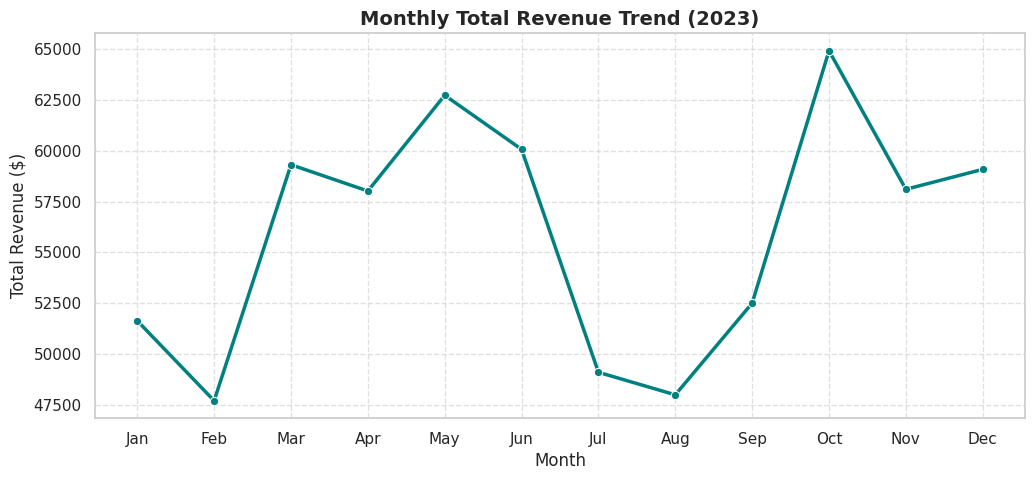

In [109]:
# Group data by month and analyse monthly revenue
# 1. Extract month name/number from pickup datetime
df_non_zero['month_num'] = df_non_zero['tpep_pickup_datetime'].dt.month
df_non_zero['month_name'] = df_non_zero['tpep_pickup_datetime'].dt.strftime('%b')

# 2. Group by month and calculate total monthly revenue and average trip revenue
monthly_revenue = df_non_zero.groupby(['month_num', 'month_name'])['total_amount'].agg(
    total_revenue='sum',
    avg_revenue_per_trip='mean',
    trip_count='count'
).reset_index()

print("--- Monthly Revenue Summary ---")
print(monthly_revenue.to_string(index=False))

# 3. Plot total monthly revenue trend
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_revenue,
    x='month_name',
    y='total_amount' if 'total_amount' in monthly_revenue else 'total_revenue',
    marker='o',
    color='teal',
    linewidth=2.5
)
plt.title('Monthly Total Revenue Trend (2023)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

--- Quarterly Revenue Breakdown ---
  quarter  total_revenue  trip_count  proportion  percentage
0  2023Q1      158635.05        5467    0.236359       23.64
1  2023Q2      180831.68        5977    0.269430       26.94
2  2023Q3      149572.27        4870    0.222855       22.29
3  2023Q4      182123.66        5892    0.271355       27.14


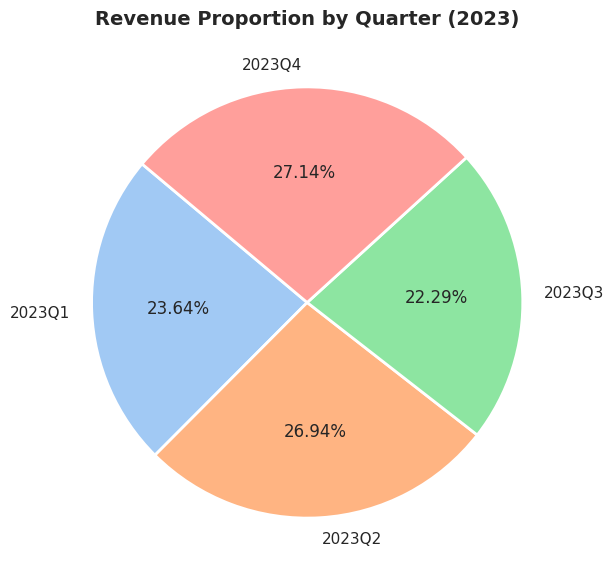

In [110]:
# Calculate proportion of each quarter
# 1. Assign Quarter based on pickup datetime
df_non_zero['quarter'] = df_non_zero['tpep_pickup_datetime'].dt.to_period('Q').astype(str)

# 2. Group by Quarter to calculate Total Revenue and Proportion
quarterly_revenue = df_non_zero.groupby('quarter')['total_amount'].agg(
    total_revenue='sum',
    trip_count='count'
).reset_index()

# 3. Calculate percentage and proportion of total revenue
total_year_revenue = quarterly_revenue['total_revenue'].sum()
quarterly_revenue['proportion'] = quarterly_revenue['total_revenue'] / total_year_revenue
quarterly_revenue['percentage'] = (quarterly_revenue['proportion'] * 100).round(2)

print("--- Quarterly Revenue Breakdown ---")
print(quarterly_revenue)

# 4. Visualize the proportion of each quarter with a Donut / Pie Chart
plt.figure(figsize=(7, 7))
plt.pie(
    quarterly_revenue['total_revenue'],
    labels=quarterly_revenue['quarter'],
    autopct='%1.2f%%',
    startangle=140,
    colors=sns.color_palette('pastel')[0:4],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
plt.title('Revenue Proportion by Quarter (2023)', fontsize=14, fontweight='bold')
plt.show()


**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

Correlation between trip_distance and fare_amount: 0.9310


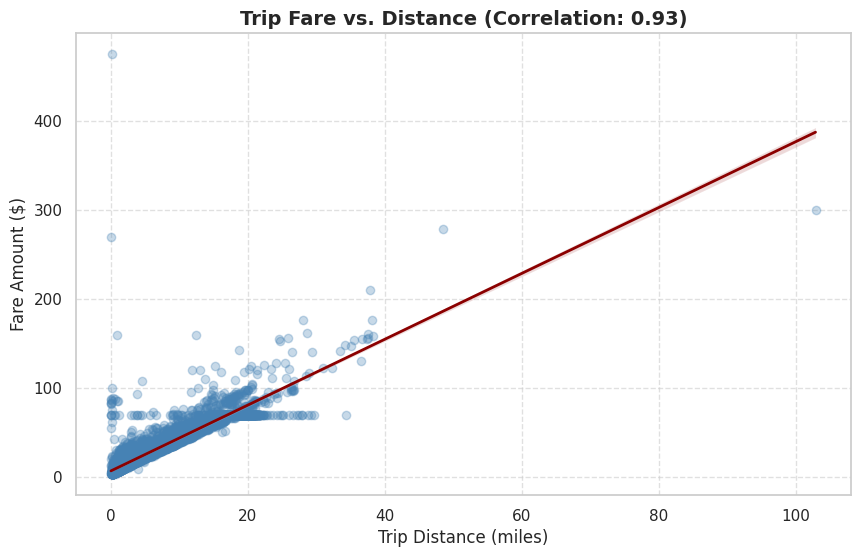

In [111]:
# Show how trip fare is affected by distance

# 1. Calculate Pearson correlation coefficient using non-zero filtered data
corr_value = df_non_zero['trip_distance'].corr(df_non_zero['fare_amount'])
print(f"Correlation between trip_distance and fare_amount: {corr_value:.4f}")

# 2. Visualize the relationship using a Scatter Plot with a Trendline
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_non_zero,
    x='trip_distance',
    y='fare_amount',
    scatter_kws={'alpha': 0.3, 'color': 'steelblue'},
    line_kws={'color': 'darkred', 'linewidth': 2}
)

plt.title(f'Trip Fare vs. Distance (Correlation: {corr_value:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Trip Distance (miles)', fontsize=12)
plt.ylabel('Fare Amount ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

Correlation between fare_amount and trip_duration: 0.8436


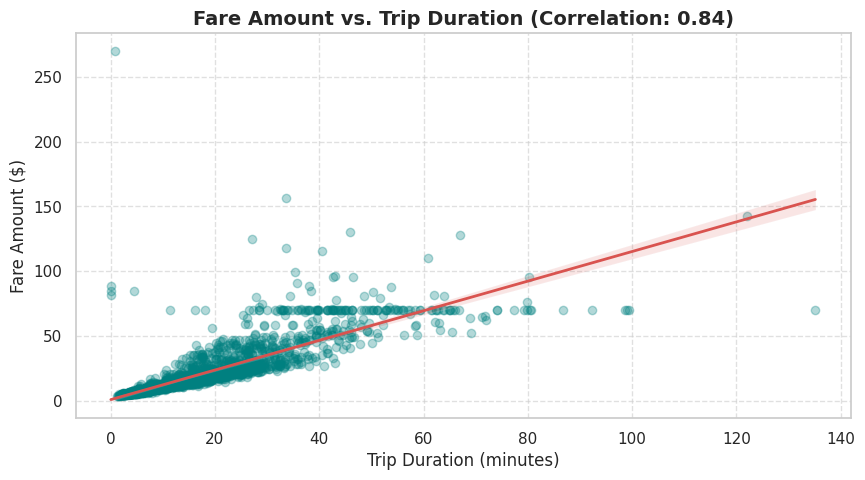

In [112]:
# Show relationship between fare and trip duration

# 1. Calculate trip duration in minutes if not already present
if 'trip_duration' not in df_non_zero.columns:
    df_non_zero['trip_duration'] = (
        df_non_zero['tpep_dropoff_datetime'] - df_non_zero['tpep_pickup_datetime']
    ).dt.total_seconds() / 60.0

# Filter out potential duration anomalies (e.g., negative or extreme values > 180 mins)
df_valid_duration = df_non_zero[(df_non_zero['trip_duration'] > 0) & (df_non_zero['trip_duration'] <= 180)]

# 2. Compute Pearson Correlation
corr_duration = df_valid_duration['fare_amount'].corr(df_valid_duration['trip_duration'])
print(f"Correlation between fare_amount and trip_duration: {corr_duration:.4f}")

# 3. Visualize using Scatter Plot with Regression Trendline
plt.figure(figsize=(10, 5))
sns.regplot(
    data=df_valid_duration.sample(min(3000, len(df_valid_duration)), random_state=42),
    x='trip_duration',
    y='fare_amount',
    scatter_kws={'alpha': 0.3, 'color': '#008080'},
    line_kws={'color': '#d9534f', 'linewidth': 2}
)

plt.title(f'Fare Amount vs. Trip Duration (Correlation: {corr_duration:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Trip Duration (minutes)', fontsize=12)
plt.ylabel('Fare Amount ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

--- Fare Summary by Passenger Count ---
 passenger_count  mean_fare  median_fare  std_fare  trip_count
               1  18.790983         13.5 16.604215       17332
               2  21.404522         14.2 18.820007        3229
               3  20.909091         14.2 19.250839         770
               4  24.586420         15.6 31.915698         405
               5  18.829151         13.5 16.091742         271
               6  17.801005         12.1 16.009091         199


/tmp/ipykernel_896/1306689534.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


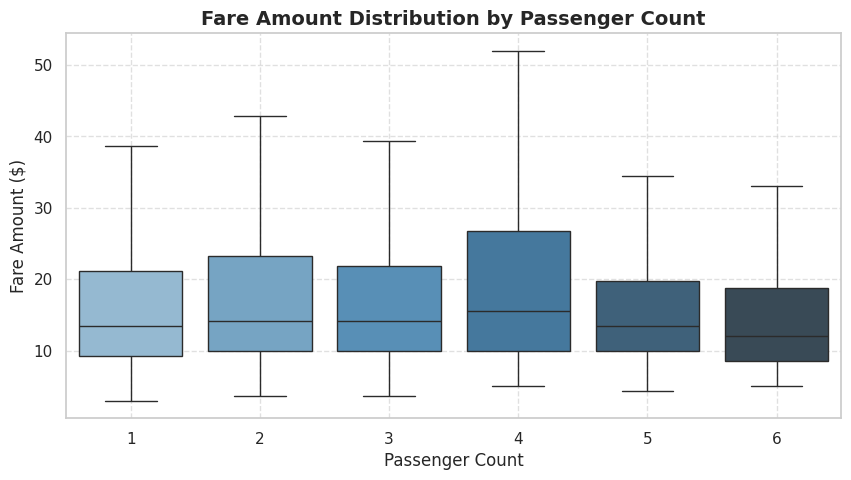

In [113]:
# Show relationship between fare and number of passengers

# 1. Summary statistics of fare_amount grouped by passenger_count
pass_fare_summary = df_non_zero.groupby('passenger_count')['fare_amount'].agg(
    mean_fare='mean',
    median_fare='median',
    std_fare='std',
    trip_count='count'
).reset_index()

print("--- Fare Summary by Passenger Count ---")
print(pass_fare_summary.to_string(index=False))

# 2. Visualize using a Boxplot to compare distributions across passenger counts
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_non_zero,
    x='passenger_count',
    y='fare_amount',
    palette='Blues_d',
    showfliers=False  # Exclude extreme outliers for visual clarity
)

plt.title('Fare Amount Distribution by Passenger Count', fontsize=14, fontweight='bold')
plt.xlabel('Passenger Count', fontsize=12)
plt.ylabel('Fare Amount ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Correlation between tip_amount and trip_distance (Credit Card Trips): 0.7980


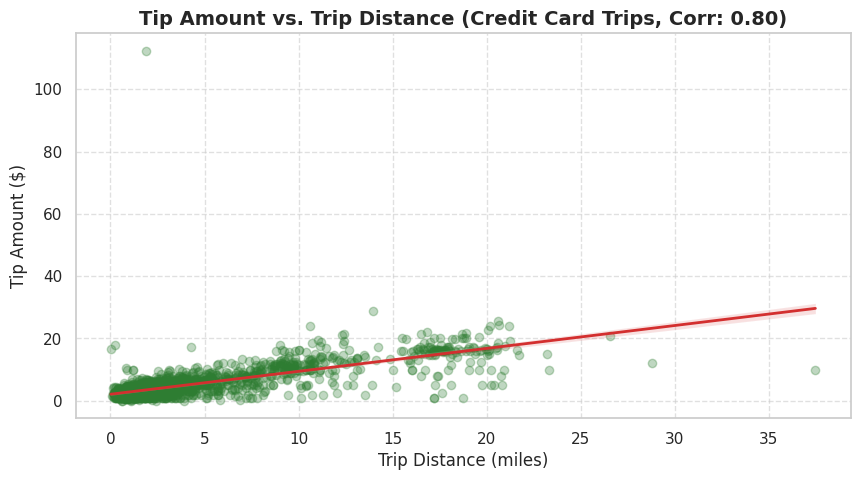

In [119]:
# Show relationship between tip and trip distance

# 1. Filter dataset for Credit Card payments only (payment_type == 1)
# Note: Cash payments (payment_type == 2) do not record tip amounts in the dataset (always $0.00).
df_credit_card = df_non_zero[df_non_zero['payment_type'] == 1].copy()

# 2. Compute Pearson Correlation Coefficient
corr_tip_dist = df_credit_card['tip_amount'].corr(df_credit_card['trip_distance'])
print(f"Correlation between tip_amount and trip_distance (Credit Card Trips): {corr_tip_dist:.4f}")

# 3. Scatter Plot with Regression Trendline
plt.figure(figsize=(10, 5))
sns.regplot(
    data=df_credit_card.sample(min(3000, len(df_credit_card)), random_state=42),
    x='trip_distance',
    y='tip_amount',
    scatter_kws={'alpha': 0.3, 'color': '#2e7d32'},
    line_kws={'color': '#d32f2f', 'linewidth': 2}
)

plt.title(f'Tip Amount vs. Trip Distance (Credit Card Trips, Corr: {corr_tip_dist:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Trip Distance (miles)', fontsize=12)
plt.ylabel('Tip Amount ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

--- Payment Type Distribution ---
payment_type payment_method  count  percentage
           1    Credit Card  23442       80.81
           2           Cash   4936       17.02
           4        Dispute    433        1.49
           3      No Charge    198        0.68


/tmp/ipykernel_896/1616170309.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


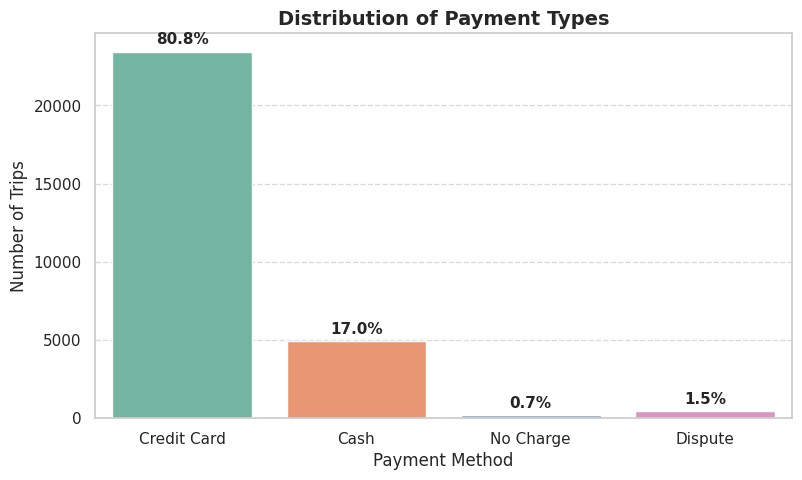

In [124]:
# Analyse the distribution of different payment types (payment_type).
# 1. Map payment_type numerical codes to readable labels based on TLC data dictionary
payment_map = {
    1: 'Credit Card',
    2: 'Cash',
    3: 'No Charge',
    4: 'Dispute',
    5: 'Unknown',
    6: 'Voided Trip'
}

# 2. Count frequencies and calculate percentages
payment_counts = df['payment_type'].value_counts().reset_index()
payment_counts.columns = ['payment_type', 'count']
#payment_counts['payment_method'] = payment_counts['payment_type'].map(payment_map).fillna('Other')
payment_counts['payment_method'] = payment_counts['payment_type'].map(payment_map)
payment_counts['percentage'] = (payment_counts['count'] / len(df)) * 100

print("--- Payment Type Distribution ---")
print(payment_counts[['payment_type', 'payment_method', 'count', 'percentage']].round(2).to_string(index=False))

# 3. Visualize using a Seaborn Countplot / Barplot
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=payment_counts,
    x='payment_method',
    y='count',
    palette='Set2'
)

# Add percentage labels above each bar
for p in ax.patches:
    height = p.get_height()
    pct = (height / len(df)) * 100
    ax.annotate(f'{pct:.1f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.title('Distribution of Payment Types', fontsize=14, fontweight='bold')
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [125]:
!pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [126]:
# import geopandas as gpd
import geopandas as gpd

# Read the shapefile using geopandas
zones = gpd.read_file('taxi_zones.shp')
# read the .shp file using gpd
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

--- Taxi Zones Info ---
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None

--- First 5 Rows ---


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


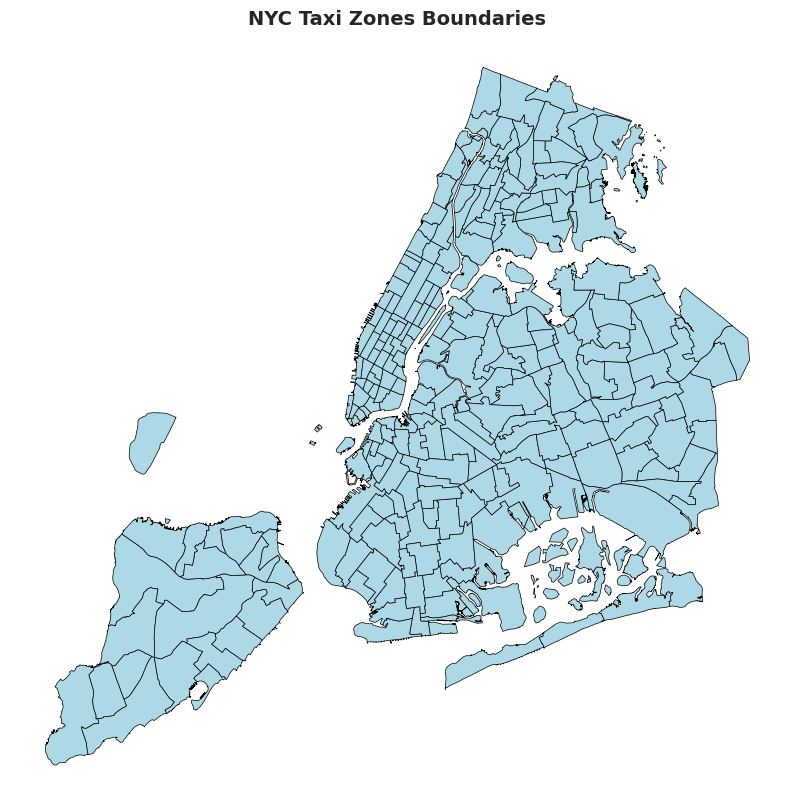

In [127]:
# print(zones.info())
# zones.plot()
print("--- Taxi Zones Info ---")
print(zones.info())
print("\n--- First 5 Rows ---")
display(zones.head())

# 3. Plot the taxi zones map
fig, ax = plt.subplots(figsize=(10, 10))
zones.plot(ax=ax, color='lightblue', edgecolor='black', linewidth=0.5)

plt.title('NYC Taxi Zones Boundaries', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [128]:
# Merge zones and trip records using locationID and PULocationID
# Merge zones GeoDataFrame with trip DataFrame using LocationID (from zones) and PULocationID (from df)
df_merged = df.merge(
    zones,
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

# Display the first few rows of the merged dataset
df_merged.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,...,trip_duration,day_of_week,month,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,2,2023-11-03 17:49:43,2023-11-03 18:01:34,1,1.89,1,141,239,1,12.8,...,11.850000,Friday,November,141.0,0.041514,0.000077,Lenox Hill West,141.0,Manhattan,"POLYGON ((994839.073 216123.698, 994786.74 216..."
1,2,2023-09-01 05:56:35,2023-09-01 06:27:49,2,17.01,3,88,1,2,84.6,...,31.233333,Friday,September,88.0,0.035205,0.000057,Financial District South,88.0,Manhattan,"POLYGON ((981547.706 196045.255, 981628.588 19..."
2,2,2023-02-07 14:47:55,2023-02-07 14:57:34,2,1.81,1,142,43,1,12.1,...,9.650000,Tuesday,February,142.0,0.038176,0.000076,Lincoln Square East,142.0,Manhattan,"POLYGON ((989380.305 218980.247, 989359.803 21..."
3,2,2023-12-18 18:48:36,2023-12-18 19:10:36,1,2.79,1,163,151,2,17.0,...,22.000000,Monday,December,163.0,0.034177,0.000041,Midtown North,163.0,Manhattan,"POLYGON ((989412.663 219020.943, 990045.841 21..."
4,2,2023-12-09 07:37:07,2023-12-09 07:41:58,1,1.23,1,229,137,1,7.9,...,4.850000,Saturday,December,229.0,0.042525,0.000095,Sutton Place/Turtle Bay North,229.0,Manhattan,"POLYGON ((994880.664 214401.395, 994724.359 21..."


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [129]:
# Group data by location and calculate the number of trips
# Group by PULocationID to calculate the total number of pickup trips per location
trip_counts = df['PULocationID'].value_counts().reset_index()
trip_counts.columns = ['LocationID', 'trip_count']

# Display the top 10 most popular pickup locations
print("--- Top 10 Pickup Locations by Trip Count ---")
display(trip_counts.head(10))


--- Top 10 Pickup Locations by Trip Count ---


,LocationID,trip_count
0,132,1559
1,237,1385
2,161,1340
3,236,1257
4,162,1081
5,186,1038
6,138,1038
7,230,996
8,142,921
9,170,888


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [130]:
# Merge trip counts back to the zones GeoDataFrame

# Merge the grouped trip counts back into the zones GeoDataFrame
zones_with_counts = zones.merge(
    trip_counts,
    on='LocationID',
    how='left'
)

# Fill missing trip counts with 0 (for zones that had no pickups)
zones_with_counts['trip_count'] = zones_with_counts['trip_count'].fillna(0)

# Display the first few rows of the updated GeoDataFrame
zones_with_counts.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,trip_count
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",8.0
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",0.0
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",1.0
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",24.0
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",0.0


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

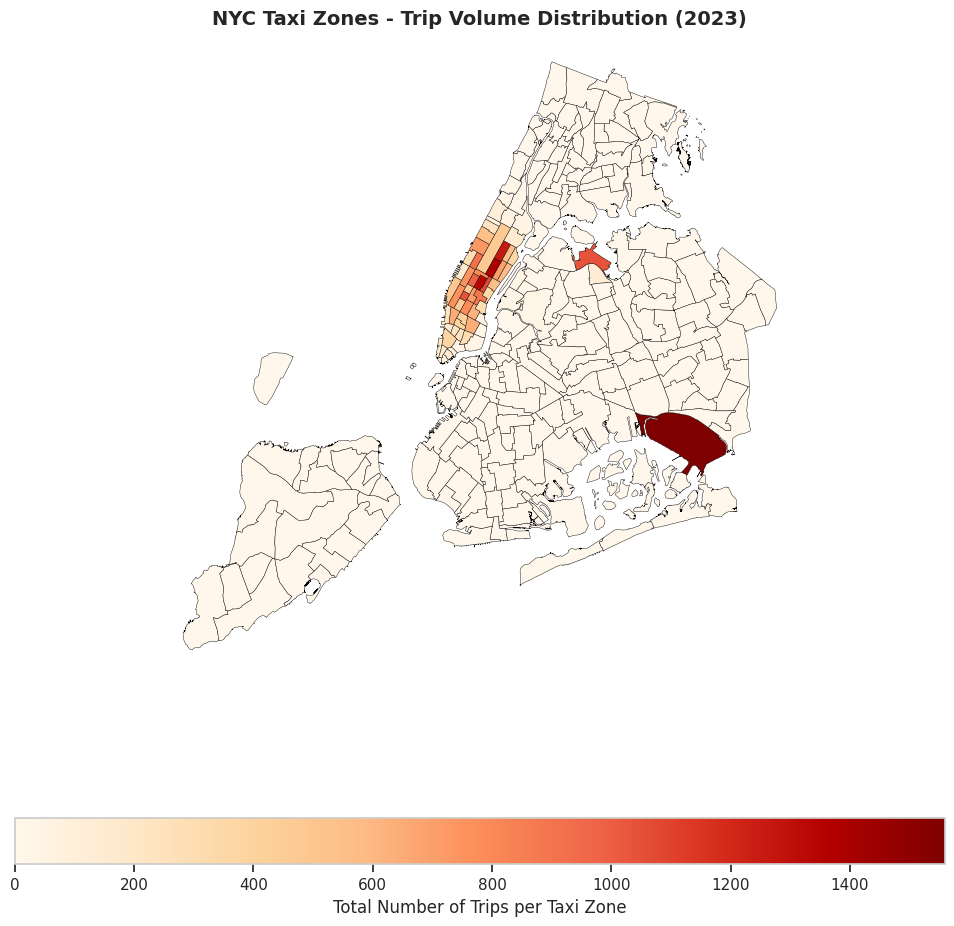

In [131]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

# Plot the map and display it
zones_with_counts.plot(
    column='trip_count',
    ax=ax,
    legend=True,
    legend_kwds={
        'label': "Total Number of Trips per Taxi Zone",
        'orientation': "horizontal"
    },
    cmap='OrRd',            # Warm color scale highlighting high-density pickup zones
    edgecolor='black',
    linewidth=0.3,
    missing_kwds={"color": "lightgrey", "label": "No Data"}
)

plt.title('NYC Taxi Zones - Trip Volume Distribution (2023)', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()



In [ ]:
# can you try displaying the zones DF sorted by the number of trips?



Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [132]:
# Find routes which have the slowest speeds at different times of the day

# 1. Ensure trip_duration (in hours) and average speed (mph) are calculated
df['trip_duration_hrs'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 3600.0

# Filter for valid non-zero trips to avoid division by zero or unrealistic speeds (> 80 mph or <= 0 mph)
df_valid_routes = df[
    (df['trip_duration_hrs'] > 0) &
    (df['trip_distance'] > 0) &
    (df['trip_duration_hrs'] <= 3)
].copy()

# 2. Group by PULocationID, DOLocationID, and pickup_hour to calculate average speed per route
route_speed = df_valid_routes.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).agg(
    avg_distance=('trip_distance', 'mean'),
    avg_duration_hrs=('trip_duration_hrs', 'mean'),
    total_trips=('trip_distance', 'count')
).reset_index()

# Speed = distance / duration
route_speed['avg_speed_mph'] = route_speed['avg_distance'] / route_speed['avg_duration_hrs']

# Filter for routes with at least 5 trips to ignore low-sample anomalies
frequent_routes = route_speed[route_speed['total_trips'] >= 5]

# 3. Find the slowest routes across different time periods of the day
slowest_routes = frequent_routes.sort_values(by=['pickup_hour', 'avg_speed_mph']).groupby('pickup_hour').head(1)

# Merge with zones data to get readable zone names for PULocationID and DOLocationID
slowest_routes = slowest_routes.merge(zones[['LocationID', 'zone']], left_on='PULocationID', right_on='LocationID', how='left') \
                               .rename(columns={'zone': 'pickup_zone'}).drop(columns=['LocationID'])

slowest_routes = slowest_routes.merge(zones[['LocationID', 'zone']], left_on='DOLocationID', right_on='LocationID', how='left') \
                               .rename(columns={'zone': 'dropoff_zone'}).drop(columns=['LocationID'])

# Display the top slowest route per hour of the day
print("--- Slowest Routes by Hour of Day ---")
display(slowest_routes[['pickup_hour', 'PULocationID', 'pickup_zone', 'DOLocationID', 'dropoff_zone', 'avg_speed_mph', 'total_trips']].round(2))

/tmp/ipykernel_896/4092066115.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  route_speed = df_valid_routes.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).agg(


--- Slowest Routes by Hour of Day ---


,pickup_hour,PULocationID,pickup_zone,DOLocationID,dropoff_zone,avg_speed_mph,total_trips
0,0,148,Lower East Side,107,Gramercy,8.62,5
1,1,264,NaN,264,NaN,12.57,11
2,6,100,Garment District,161,Midtown Center,7.73,6
3,7,141,Lenox Hill West,237,Upper East Side South,7.38,5
4,8,161,Midtown Center,230,Times Sq/Theatre District,3.43,6
5,9,186,Penn Station/Madison Sq West,161,Midtown Center,3.79,8
6,10,186,Penn Station/Madison Sq West,163,Midtown North,3.22,5
7,11,186,Penn Station/Madison Sq West,230,Times Sq/Theatre District,2.89,6
8,12,164,Midtown South,170,Murray Hill,3.83,5
9,13,161,Midtown Center,161,Midtown Center,3.58,5


How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

/tmp/ipykernel_896/103137638.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='pickup_hour', y='trip_count', data=hourly_counts, palette='viridis')


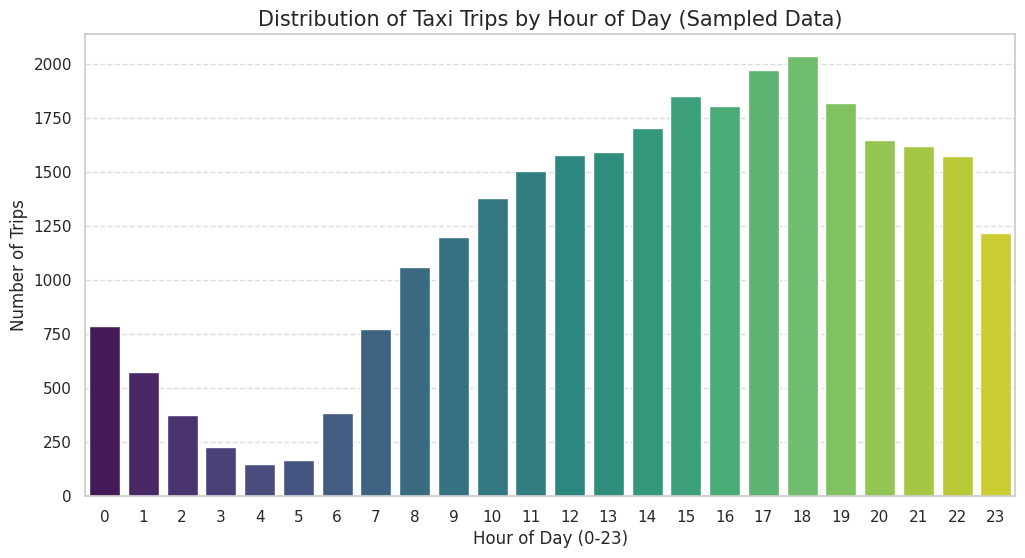

The busiest hour is 18:00 with 2036 sampled trips.


In [133]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group by pickup_hour and count trips
hourly_counts = df.groupby('pickup_hour').size().reset_index(name='trip_count')

# Create the visualization
plt.figure(figsize=(12, 6))
sns.barplot(x='pickup_hour', y='trip_count', data=hourly_counts, palette='viridis')

# Identify the busiest hour
busiest_hour = hourly_counts.loc[hourly_counts['trip_count'].idxmax()]

plt.title('Distribution of Taxi Trips by Hour of Day (Sampled Data)', fontsize=15)
plt.xlabel('Hour of Day (0-23)', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

print(f"The busiest hour is {int(busiest_hour['pickup_hour'])}:00 with {int(busiest_hour['trip_count'])} sampled trips.")

Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [134]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.05

# 1. Calculate trip counts per hour in the sampled dataset
hourly_counts = df['pickup_hour'].value_counts()

# 2. Identify the five busiest hours
busiest_sampled_hours = hourly_counts.head(5)

# 3. Scale up the sampled counts to estimate total actual trips
actual_hourly_trips = (busiest_sampled_hours / sample_fraction).astype(int)

# Create a clean summary DataFrame
busiest_summary = pd.DataFrame({
    'Sampled_Trip_Count': busiest_sampled_hours.values,
    'Estimated_Actual_Trip_Count': actual_hourly_trips.values
}, index=[f"{hour}:00" for hour in busiest_sampled_hours.index])

busiest_summary.index.name = 'Hour'

print("--- Top 5 Busiest Hours (Sampled vs. Actual Estimated Trips) ---")
display(busiest_summary)



--- Top 5 Busiest Hours (Sampled vs. Actual Estimated Trips) ---


,Sampled_Trip_Count,Estimated_Actual_Trip_Count
Hour,,
18:00,2036,40720
17:00,1973,39460
15:00,1851,37020
19:00,1821,36420
16:00,1805,36100


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

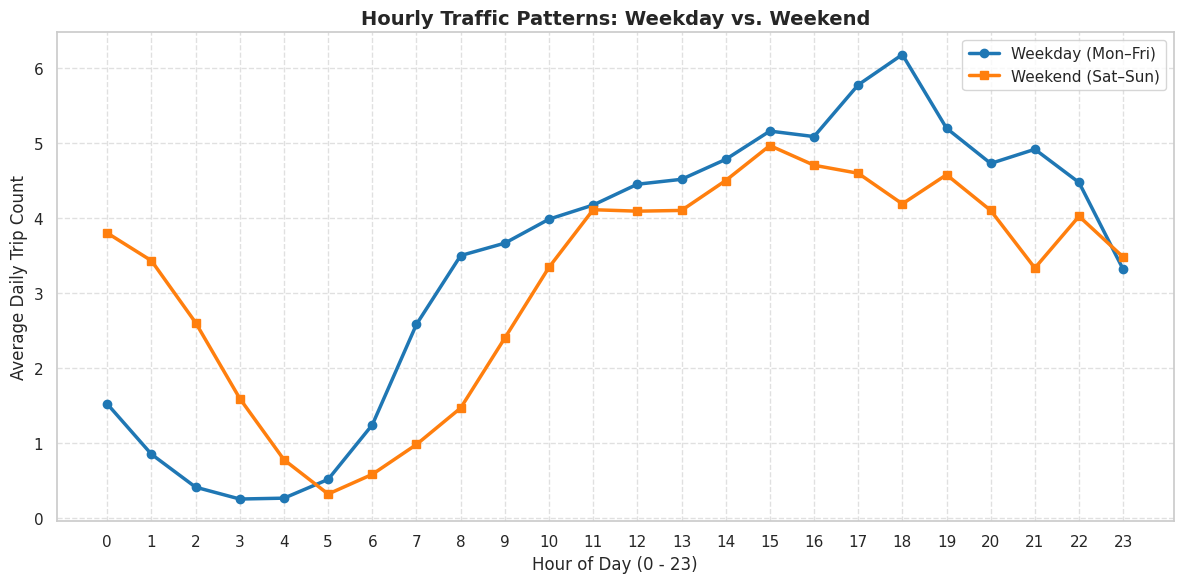

In [135]:
# Compare traffic trends for the week days and weekends

# 1. Extract day of week and classify into Weekday vs. Weekend
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek  # 0=Mon, 6=Sun
df['day_type'] = df['day_of_week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

# 2. Calculate average hourly trip counts per day type
# Normalize by the number of unique days to compare average daily traffic
unique_weekdays = df[df['day_type'] == 'Weekday']['tpep_pickup_datetime'].dt.date.nunique()
unique_weekends = df[df['day_type'] == 'Weekend']['tpep_pickup_datetime'].dt.date.nunique()

hourly_counts = df.groupby(['pickup_hour', 'day_type']).size().unstack(fill_value=0)
hourly_counts['Weekday_Avg'] = hourly_counts['Weekday'] / unique_weekdays
hourly_counts['Weekend_Avg'] = hourly_counts['Weekend'] / unique_weekends

# 3. Visualize using Line Plot
plt.figure(figsize=(12, 6))
plt.plot(hourly_counts.index, hourly_counts['Weekday_Avg'], marker='o', linewidth=2.5, label='Weekday (Mon–Fri)', color='#1f77b4')
plt.plot(hourly_counts.index, hourly_counts['Weekend_Avg'], marker='s', linewidth=2.5, label='Weekend (Sat–Sun)', color='#ff7f0e')

plt.title('Hourly Traffic Patterns: Weekday vs. Weekend', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Average Daily Trip Count', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

--- Top 10 Pickup Zones ---


,LocationID,pickup_count,zone,borough
0,132,1559,JFK Airport,Queens
1,237,1385,Upper East Side South,Manhattan
2,161,1340,Midtown Center,Manhattan
3,236,1257,Upper East Side North,Manhattan
4,162,1081,Midtown East,Manhattan
5,186,1038,Penn Station/Madison Sq West,Manhattan
6,138,1038,LaGuardia Airport,Queens
7,230,996,Times Sq/Theatre District,Manhattan
8,142,921,Lincoln Square East,Manhattan
9,170,888,Murray Hill,Manhattan



--- Top 10 Dropoff Zones ---


,LocationID,dropoff_count,zone,borough
0,236,1290,Upper East Side North,Manhattan
1,237,1186,Upper East Side South,Manhattan
2,161,1141,Midtown Center,Manhattan
3,230,884,Times Sq/Theatre District,Manhattan
4,170,832,Murray Hill,Manhattan
5,142,829,Lincoln Square East,Manhattan
6,141,812,Lenox Hill West,Manhattan
7,239,802,Upper West Side South,Manhattan
8,162,788,Midtown East,Manhattan
9,68,746,East Chelsea,Manhattan


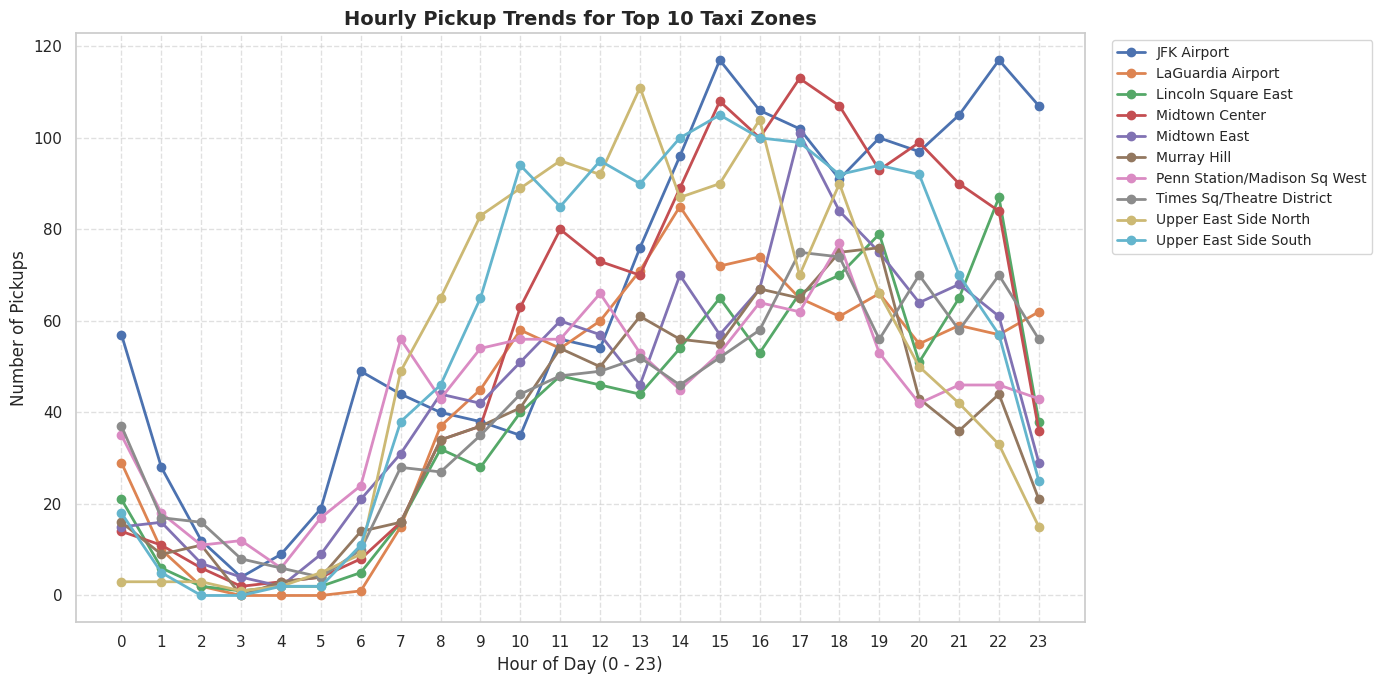

In [136]:
# Find top 10 pickup and dropoff zones

# 1. Calculate top 10 pickup zones
top_pu_counts = df['PULocationID'].value_counts().head(10).reset_index()
top_pu_counts.columns = ['LocationID', 'pickup_count']

# Merge with zones GeoDataFrame to retrieve Zone names and Boroughs
top_pu = top_pu_counts.merge(zones[['LocationID', 'zone', 'borough']], on='LocationID', how='left')

print("--- Top 10 Pickup Zones ---")
display(top_pu)

# 2. Calculate top 10 dropoff zones
top_do_counts = df['DOLocationID'].value_counts().head(10).reset_index()
top_do_counts.columns = ['LocationID', 'dropoff_count']

# Merge with zones GeoDataFrame
top_do = top_do_counts.merge(zones[['LocationID', 'zone', 'borough']], on='LocationID', how='left')

print("\n--- Top 10 Dropoff Zones ---")
display(top_do)

# 3. Analyze Hourly Trends for Top 10 Pickup Zones
top_pu_ids = top_pu['LocationID'].tolist()
df_top_pu = df[df['PULocationID'].isin(top_pu_ids)].copy()

# Map zone names to pickup location IDs
zone_dict = zones.set_index('LocationID')['zone'].to_dict()
df_top_pu['PULocationName'] = df_top_pu['PULocationID'].map(zone_dict)

# Group by hour and pickup location
hourly_pu = df_top_pu.groupby(['pickup_hour', 'PULocationName']).size().unstack(fill_value=0)

# 4. Plot Hourly Trends for Top Pickup Zones
plt.figure(figsize=(14, 7))
for zone_name in hourly_pu.columns:
    plt.plot(hourly_pu.index, hourly_pu[zone_name], marker='o', linewidth=2, label=zone_name)

plt.title('Hourly Pickup Trends for Top 10 Taxi Zones', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Number of Pickups', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [137]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

# 1. Calculate total pickups per zone
pu_counts = df['PULocationID'].value_counts().reset_index()
pu_counts.columns = ['LocationID', 'pickup_count']

# 2. Calculate total dropoffs per zone
do_counts = df['DOLocationID'].value_counts().reset_index()
do_counts.columns = ['LocationID', 'dropoff_count']

# 3. Merge pickup and dropoff counts with zones GeoDataFrame
ratio_df = zones[['LocationID', 'zone', 'borough']].merge(pu_counts, on='LocationID', how='left')
ratio_df = ratio_df.merge(do_counts, on='LocationID', how='left')

# Fill missing counts with 0
ratio_df['pickup_count'] = ratio_df['pickup_count'].fillna(0)
ratio_df['dropoff_count'] = ratio_df['dropoff_count'].fillna(0)

# Filter out zones with extremely low overall activity to prevent division by zero or distortion
active_zones = ratio_df[(ratio_df['pickup_count'] >= 10) & (ratio_df['dropoff_count'] >= 10)].copy()

# 4. Calculate pickup/dropoff ratio
active_zones['pu_do_ratio'] = active_zones['pickup_count'] / active_zones['dropoff_count']

# Top 10 Zones (Highest Pickup to Dropoff Ratio -> Origin/Net Exporters)
top_10_ratio = active_zones.sort_values(by='pu_do_ratio', ascending=False).head(10)

# Bottom 10 Zones (Lowest Pickup to Dropoff Ratio -> Destination/Net Importers)
bottom_10_ratio = active_zones.sort_values(by='pu_do_ratio', ascending=True).head(10)

print("--- Top 10 Pickup/Dropoff Ratios (Net Pickup/Origin Zones) ---")
display(top_10_ratio[['LocationID', 'zone', 'borough', 'pickup_count', 'dropoff_count', 'pu_do_ratio']].round(2))

print("\n--- Bottom 10 Pickup/Dropoff Ratios (Net Dropoff/Destination Zones) ---")
display(bottom_10_ratio[['LocationID', 'zone', 'borough', 'pickup_count', 'dropoff_count', 'pu_do_ratio']].round(2))

--- Top 10 Pickup/Dropoff Ratios (Net Pickup/Origin Zones) ---


,LocationID,zone,borough,pickup_count,dropoff_count,pu_do_ratio
69,70,East Elmhurst,Queens,133.0,25.0,5.32
131,132,JFK Airport,Queens,1559.0,346.0,4.51
137,138,LaGuardia Airport,Queens,1038.0,367.0,2.83
185,186,Penn Station/Madison Sq West,Manhattan,1038.0,628.0,1.65
260,261,World Trade Center,Manhattan,155.0,109.0,1.42
161,162,Midtown East,Manhattan,1081.0,788.0,1.37
113,114,Greenwich Village South,Manhattan,381.0,280.0,1.36
42,43,Central Park,Manhattan,469.0,360.0,1.30
112,113,Greenwich Village North,Manhattan,419.0,337.0,1.24
248,249,West Village,Manhattan,651.0,528.0,1.23



--- Bottom 10 Pickup/Dropoff Ratios (Net Dropoff/Destination Zones) ---


,LocationID,zone,borough,pickup_count,dropoff_count,pu_do_ratio
243,244,Washington Heights South,Manhattan,11.0,88.0,0.12
180,181,Park Slope,Brooklyn,11.0,84.0,0.13
41,42,Central Harlem North,Manhattan,20.0,99.0,0.20
24,25,Boerum Hill,Brooklyn,12.0,53.0,0.23
3,4,Alphabet City,Manhattan,24.0,94.0,0.26
128,129,Jackson Heights,Queens,10.0,39.0,0.26
115,116,Hamilton Heights,Manhattan,13.0,50.0,0.26
96,97,Fort Greene,Brooklyn,12.0,46.0,0.26
6,7,Astoria,Queens,24.0,87.0,0.28
64,65,Downtown Brooklyn/MetroTech,Brooklyn,13.0,47.0,0.28


**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [138]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones
# 1. Filter dataset for night hours (11 PM / 23:00 to 5 AM / 05:00)
# Night hours include hours 23, 0, 1, 2, 3, 4, 5
df_night = df[(df['pickup_hour'] >= 23) | (df['pickup_hour'] <= 5)].copy()

# 2. Find Top 10 Pickup Zones during night hours
top_night_pu = df_night['PULocationID'].value_counts().head(10).reset_index()
top_night_pu.columns = ['LocationID', 'night_pickup_count']
top_night_pu = top_night_pu.merge(zones[['LocationID', 'zone', 'borough']], on='LocationID', how='left')

# 3. Find Top 10 Dropoff Zones during night hours
top_night_do = df_night['DOLocationID'].value_counts().head(10).reset_index()
top_night_do.columns = ['LocationID', 'night_dropoff_count']
top_night_do = top_night_do.merge(zones[['LocationID', 'zone', 'borough']], on='LocationID', how='left')

# Display Top 10 Night Pickups
print("--- Top 10 Pickup Zones During Night Hours (11 PM - 5 AM) ---")
display(top_night_pu)

# Display Top 10 Night Dropoffs
print("\n--- Top 10 Dropoff Zones During Night Hours (11 PM - 5 AM) ---")
display(top_night_do)


--- Top 10 Pickup Zones During Night Hours (11 PM - 5 AM) ---


,LocationID,night_pickup_count,zone,borough
0,79,248,East Village,Manhattan
1,132,236,JFK Airport,Queens
2,249,212,West Village,Manhattan
3,48,180,Clinton East,Manhattan
4,148,147,Lower East Side,Manhattan
5,230,144,Times Sq/Theatre District,Manhattan
6,186,142,Penn Station/Madison Sq West,Manhattan
7,114,135,Greenwich Village South,Manhattan
8,164,104,Midtown South,Manhattan
9,138,103,LaGuardia Airport,Queens



--- Top 10 Dropoff Zones During Night Hours (11 PM - 5 AM) ---


,LocationID,night_dropoff_count,zone,borough
0,79,142,East Village,Manhattan
1,107,107,Gramercy,Manhattan
2,68,103,East Chelsea,Manhattan
3,48,102,Clinton East,Manhattan
4,170,90,Murray Hill,Manhattan
5,141,87,Lenox Hill West,Manhattan
6,230,81,Times Sq/Theatre District,Manhattan
7,249,72,West Village,Manhattan
8,246,70,West Chelsea/Hudson Yards,Manhattan
9,233,70,UN/Turtle Bay South,Manhattan


Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

--- Revenue Share: Daytime vs. Nighttime ---


,time_of_day,total_revenue,trip_count,avg_fare,revenue_share_pct
0,Day (6AM-10PM),751159.30,25509,29.45,87.83
1,Night (11PM-5AM),104041.96,3500,29.73,12.17


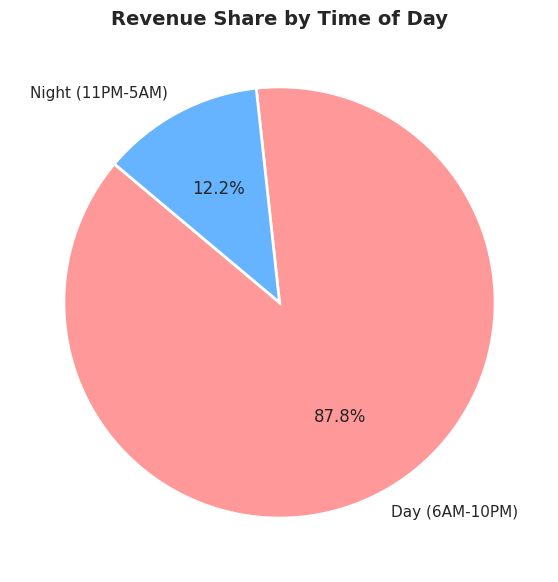

In [139]:
# Filter for night hours (11 PM to 5 AM)

# 1. Define time windows: Nighttime (11 PM to 5 AM / 23:00-05:00) vs. Daytime (6 AM to 10 PM / 06:00-22:00)
# Ensure pickup_hour column is present
df['pickup_hour'] = pd.to_datetime(df['tpep_pickup_datetime']).dt.hour

# Classify trips as 'Night' or 'Day'
df['time_of_day'] = df['pickup_hour'].apply(
    lambda h: 'Night (11PM-5AM)' if (h >= 23 or h <= 5) else 'Day (6AM-10PM)'
)

# 2. Calculate total revenue (total_amount) by time of day
revenue_summary = df.groupby('time_of_day')['total_amount'].agg(
    total_revenue='sum',
    trip_count='count',
    avg_fare='mean'
).reset_index()

# Calculate revenue share percentage
total_revenue_all = revenue_summary['total_revenue'].sum()
revenue_summary['revenue_share_pct'] = (revenue_summary['total_revenue'] / total_revenue_all) * 100

print("--- Revenue Share: Daytime vs. Nighttime ---")
display(revenue_summary.round(2))

# 3. Visualize Revenue Share using a Donut / Pie Chart
plt.figure(figsize=(7, 7))
colors = ['#ff9999', '#66b3ff']
plt.pie(
    revenue_summary['revenue_share_pct'],
    labels=revenue_summary['time_of_day'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
plt.title('Revenue Share by Time of Day', fontsize=14, fontweight='bold')
plt.show()

##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

--- Fare per Mile per Passenger Analysis ---


,passenger_count,total_trips,avg_fare_amount,avg_trip_distance,avg_fare_per_mile,avg_fare_per_mile_per_passenger
0,1,22057,19.00,3.34,11.48,11.48
1,2,4251,21.85,4.00,17.75,8.88
2,3,1096,21.84,3.94,13.07,4.36
3,4,592,23.63,3.99,13.15,3.29
4,5,342,19.44,3.48,8.74,1.75
5,6,258,17.66,3.08,8.90,1.48


/tmp/ipykernel_896/1857940146.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


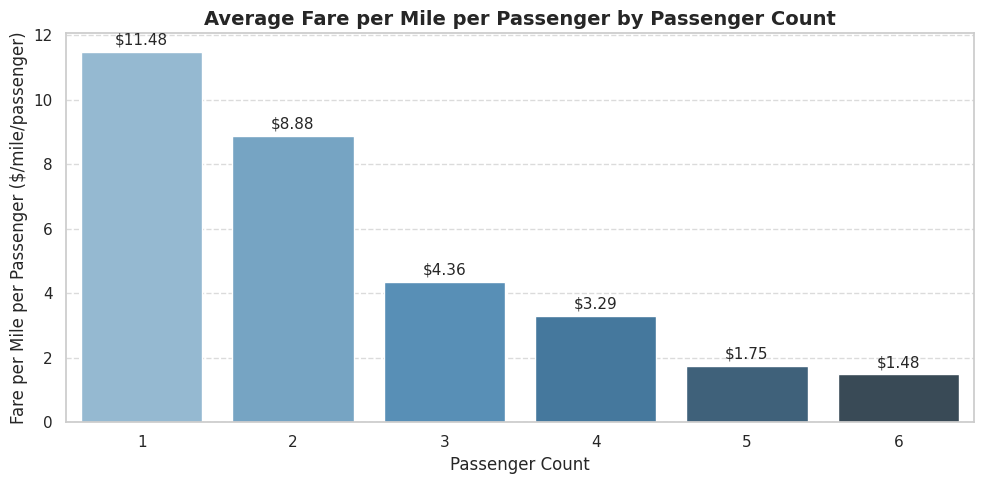

In [142]:
# Analyse the fare per mile per passenger for different passenger counts
## 1. Filter out invalid rows (zero/negative distance, zero/negative fare, zero or missing passenger counts)
df_valid_fare = df[
    (df['trip_distance'] > 0) &
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] <= 6)  # Standard taxi capacity max limit
].copy()

# 2. Calculate Fare per Mile for each trip
df_valid_fare['fare_per_mile'] = df_valid_fare['fare_amount'] / df_valid_fare['trip_distance']

# 3. Calculate Fare per Mile per Passenger
df_valid_fare['fare_per_mile_per_passenger'] = df_valid_fare['fare_per_mile'] / df_valid_fare['passenger_count']

# 4. Aggregate by passenger count
passenger_fare_analysis = df_valid_fare.groupby('passenger_count').agg(
    total_trips=('fare_amount', 'count'),
    avg_fare_amount=('fare_amount', 'mean'),
    avg_trip_distance=('trip_distance', 'mean'),
    avg_fare_per_mile=('fare_per_mile', 'mean'),
    avg_fare_per_mile_per_passenger=('fare_per_mile_per_passenger', 'mean')
).reset_index()

# Round values for display
passenger_fare_analysis = passenger_fare_analysis.round(2)

print("--- Fare per Mile per Passenger Analysis ---")
display(passenger_fare_analysis)

# 5. Visualize the Fare per Mile per Passenger
plt.figure(figsize=(10, 5))
sns.barplot(
    data=passenger_fare_analysis,
    x='passenger_count',
    y='avg_fare_per_mile_per_passenger',
    palette='Blues_d'
)

plt.title('Average Fare per Mile per Passenger by Passenger Count', fontsize=14, fontweight='bold')
plt.xlabel('Passenger Count', fontsize=12)
plt.ylabel('Fare per Mile per Passenger ($/mile/passenger)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add data labels on top of bars
for p in plt.gca().patches:
    plt.gca().annotate(
        f"${p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, xytext=(0, 3),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()



**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

--- Average Fare per Mile ($/mile) by Day and Hour ---


day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
pickup_hour,,,,,,,
0,5.42,5.92,5.85,6.21,6.61,6.59,6.83
1,5.63,5.36,6.85,6.30,6.45,6.95,6.45
2,5.58,7.02,5.98,5.69,5.46,7.26,6.52
3,5.78,5.20,5.72,6.45,6.49,6.59,6.42
4,4.97,6.54,5.88,7.91,5.38,5.71,6.27
5,7.08,5.89,5.90,6.17,5.41,6.02,6.04
6,6.34,5.98,6.63,6.70,5.93,6.83,5.16
7,7.20,6.83,7.56,6.78,7.20,6.05,5.61
8,7.18,8.26,8.15,8.10,7.42,6.15,6.35


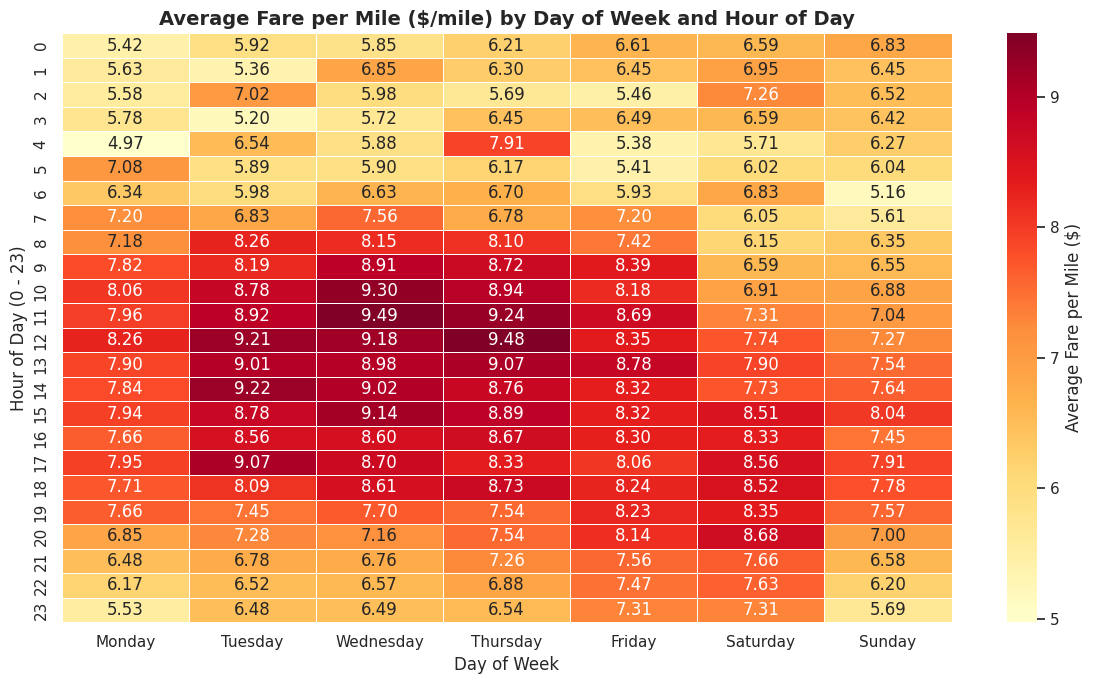

/tmp/ipykernel_896/3370951762.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_fpm.index, y=daily_fpm.values, ax=axes[0], palette='Blues_d')
/tmp/ipykernel_896/3370951762.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(days_order, rotation=45)


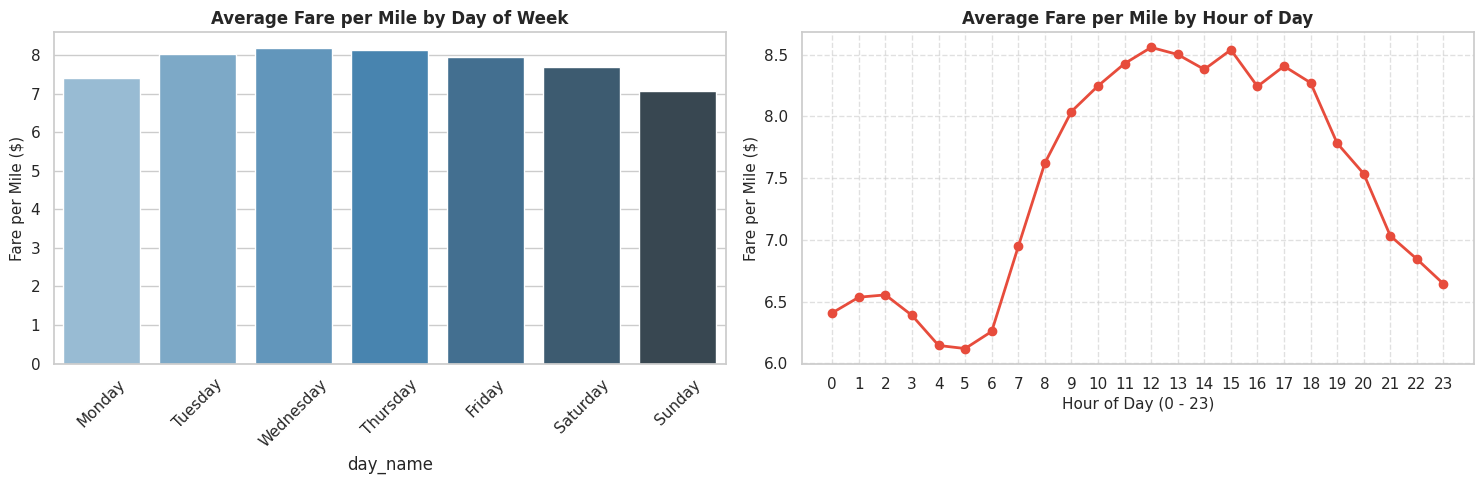

In [143]:
# Compare the average fare per mile for different days and for different times of the day
## 1. Ensure required time features and clean fare per mile metrics are prepared
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_name'] = df['tpep_pickup_datetime'].dt.day_name()

# Filter out non-positive fare amounts and trip distances to avoid division issues/inf values
df_valid_fpm = df[(df['trip_distance'] > 0) & (df['fare_amount'] > 0)].copy()
df_valid_fpm['fare_per_mile'] = df_valid_fpm['fare_amount'] / df_valid_fpm['trip_distance']

# Filter out extreme anomalies (> $50/mile) for cleaner aggregation
df_valid_fpm = df_valid_fpm[df_valid_fpm['fare_per_mile'] <= 50]

# 2. Define Day Order
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Aggregate average fare per mile by day of week and hour of day
fpm_pivot = df_valid_fpm.pivot_table(
    index='pickup_hour',
    columns='day_name',
    values='fare_per_mile',
    aggfunc='mean'
)[days_order]

print("--- Average Fare per Mile ($/mile) by Day and Hour ---")
display(fpm_pivot.round(2))

# 3. Visualization: Heatmap of Fare per Mile Across Days and Hours
plt.figure(figsize=(12, 7))
sns.heatmap(
    fpm_pivot,
    cmap='YlOrRd',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Average Fare per Mile ($)'}
)

plt.title('Average Fare per Mile ($/mile) by Day of Week and Hour of Day', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Hour of Day (0 - 23)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. Overall Comparison: By Day of Week and By Hour of Day (Line Plots)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Fare per mile by day of week
daily_fpm = df_valid_fpm.groupby('day_name')['fare_per_mile'].mean().reindex(days_order)
sns.barplot(x=daily_fpm.index, y=daily_fpm.values, ax=axes[0], palette='Blues_d')
axes[0].set_title('Average Fare per Mile by Day of Week', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fare per Mile ($)', fontsize=11)
axes[0].set_xticklabels(days_order, rotation=45)

# Fare per mile by hour of day (Fixed color parameter with '#' prefix)
hourly_fpm = df_valid_fpm.groupby('pickup_hour')['fare_per_mile'].mean()
axes[1].plot(hourly_fpm.index, hourly_fpm.values, marker='o', color='#e74c3c', linewidth=2)
axes[1].set_title('Average Fare per Mile by Hour of Day', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[1].set_ylabel('Fare per Mile ($)', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

--- Average Fare per Mile ($/mile) by Vendor and Hour ---


/tmp/ipykernel_896/1954521364.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  vendor_hourly_fpm = df_vendor_fpm.groupby(['pickup_hour', 'Vendor_Name'])['fare_per_mile'].mean().unstack()


Vendor_Name,Creative Mobile Tech (Vendor 1),VeriFone Inc (Vendor 2)
pickup_hour,,
0,6.26,6.45
1,6.70,6.48
2,7.29,6.28
3,6.36,6.39
4,6.24,6.10
5,5.73,6.31
6,6.40,6.20
7,6.92,6.96
8,7.82,7.54


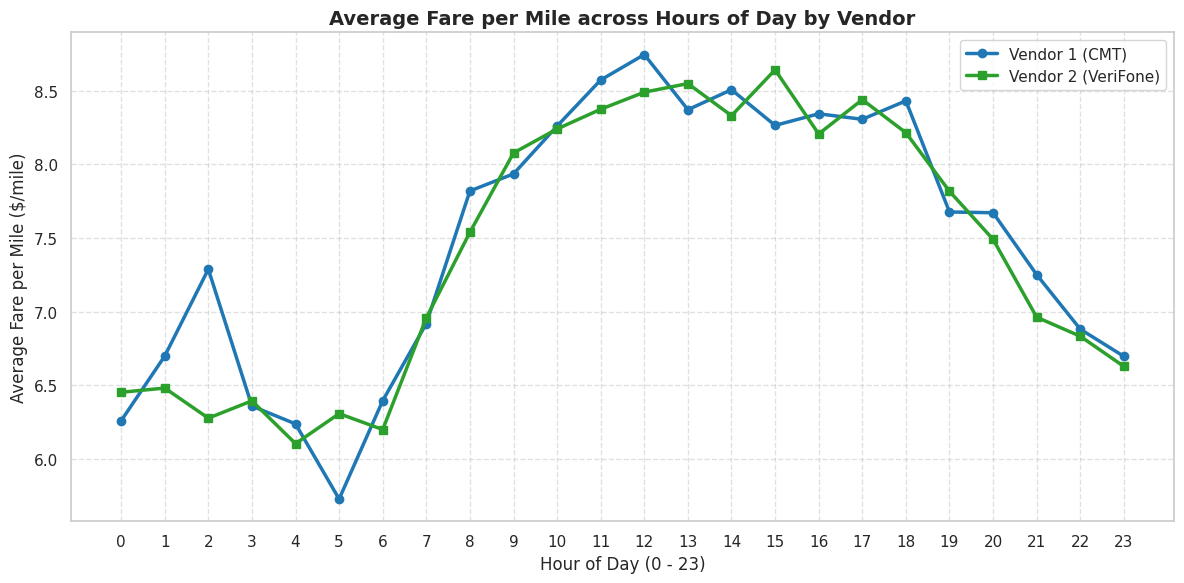

In [144]:
# Compare fare per mile for different vendors

# 1. Filter valid non-zero trip distances and positive fare amounts
df_vendor_fpm = df[(df['trip_distance'] > 0) & (df['fare_amount'] > 0)].copy()

# Calculate fare per mile
df_vendor_fpm['fare_per_mile'] = df_vendor_fpm['fare_amount'] / df_vendor_fpm['trip_distance']

# Filter out extreme outliers (> $50/mile) for reliable statistics
df_vendor_fpm = df_vendor_fpm[df_vendor_fpm['fare_per_mile'] <= 50]

# Map VendorID numerical codes to vendor names as per NYC TLC Data Dictionary
# 1 = Creative Mobile Technologies, LLC (CMT), 2 = VeriFone Inc.
vendor_map = {1: 'Creative Mobile Tech (Vendor 1)', 2: 'VeriFone Inc (Vendor 2)'}
df_vendor_fpm['Vendor_Name'] = df_vendor_fpm['VendorID'].map(vendor_map)

# 2. Aggregate average fare per mile by hour of day and vendor
vendor_hourly_fpm = df_vendor_fpm.groupby(['pickup_hour', 'Vendor_Name'])['fare_per_mile'].mean().unstack()

print("--- Average Fare per Mile ($/mile) by Vendor and Hour ---")
display(vendor_hourly_fpm.round(2))

# 3. Visualize the comparison using a Line Plot
plt.figure(figsize=(12, 6))
plt.plot(vendor_hourly_fpm.index, vendor_hourly_fpm['Creative Mobile Tech (Vendor 1)'],
         marker='o', linewidth=2.5, label='Vendor 1 (CMT)', color='#1f77b4')
plt.plot(vendor_hourly_fpm.index, vendor_hourly_fpm['VeriFone Inc (Vendor 2)'],
         marker='s', linewidth=2.5, label='Vendor 2 (VeriFone)', color='#2ca02c')

plt.title('Average Fare per Mile across Hours of Day by Vendor', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Average Fare per Mile ($/mile)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


--- Tiered Fare per Mile Summary by Vendor ---


/tmp/ipykernel_896/3704024194.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tiered_summary = df_tiered.groupby(['distance_tier', 'Vendor_Name']).agg(


,distance_tier,Vendor_Name,total_trips,avg_distance,avg_fare_amount,avg_fare_per_mile
0,Tier 1: Short (<= 2 miles),Creative Mobile Tech (Vendor 1),4270,1.15,9.88,9.49
1,Tier 1: Short (<= 2 miles),VeriFone Inc (Vendor 2),11542,1.16,10.18,9.47
2,Tier 2: Medium (2 - 5 miles),Creative Mobile Tech (Vendor 1),1962,3.01,18.81,6.36
3,Tier 2: Medium (2 - 5 miles),VeriFone Inc (Vendor 2),5751,3.00,19.28,6.56
4,Tier 3: Long (> 5 miles),Creative Mobile Tech (Vendor 1),1145,11.73,49.38,4.42
5,Tier 3: Long (> 5 miles),VeriFone Inc (Vendor 2),3799,11.67,50.59,4.52



--- Average Fare per Mile ($/mile) Side-by-Side Comparison ---


/tmp/ipykernel_896/3704024194.py:38: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  tier_pivot = df_tiered.pivot_table(


Vendor_Name,Creative Mobile Tech (Vendor 1),VeriFone Inc (Vendor 2)
distance_tier,,
Tier 1: Short (<= 2 miles),9.49,9.47
Tier 2: Medium (2 - 5 miles),6.36,6.56
Tier 3: Long (> 5 miles),4.42,4.52


/tmp/ipykernel_896/3704024194.py:50: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(


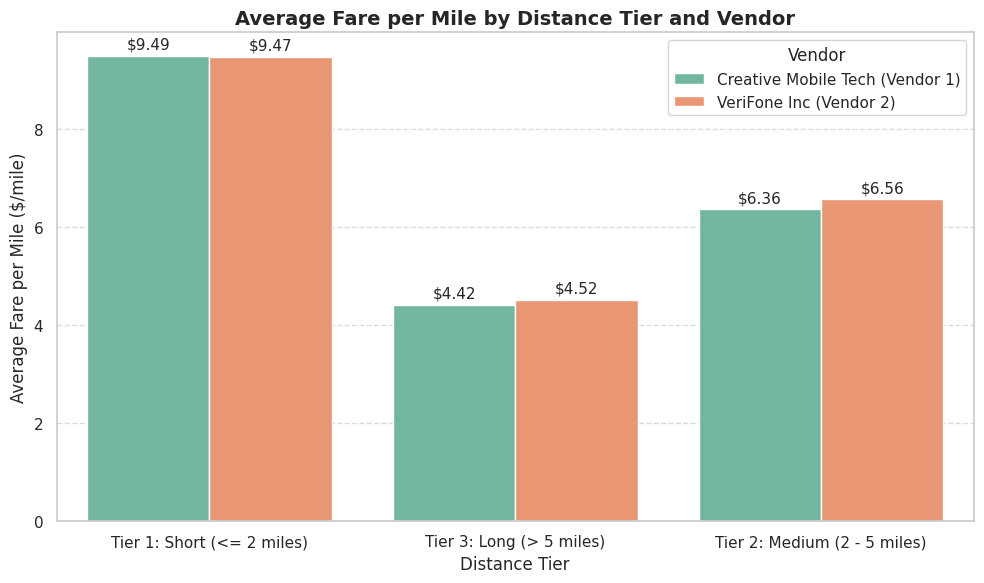

In [145]:
# Defining distance tiers
# 1. Filter out non-positive trip distances and fare amounts
df_tiered = df[(df['trip_distance'] > 0) & (df['fare_amount'] > 0)].copy()

# Map VendorIDs to readable vendor names
vendor_map = {1: 'Creative Mobile Tech (Vendor 1)', 2: 'VeriFone Inc (Vendor 2)'}
df_tiered['Vendor_Name'] = df_tiered['VendorID'].map(vendor_map)

# Calculate base fare per mile
df_tiered['fare_per_mile'] = df_tiered['fare_amount'] / df_tiered['trip_distance']

# Filter extreme outliers (> $50/mile) for reliable metrics
df_tiered = df_tiered[df_tiered['fare_per_mile'] <= 50]

# 2. Define distance tiers
def assign_distance_tier(dist):
    if dist <= 2.0:
        return 'Tier 1: Short (<= 2 miles)'
    elif 2.0 < dist <= 5.0:
        return 'Tier 2: Medium (2 - 5 miles)'
    else:
        return 'Tier 3: Long (> 5 miles)'

df_tiered['distance_tier'] = df_tiered['trip_distance'].apply(assign_distance_tier)

# 3. Aggregate average fare per mile by Distance Tier and Vendor
tiered_summary = df_tiered.groupby(['distance_tier', 'Vendor_Name']).agg(
    total_trips=('fare_amount', 'count'),
    avg_distance=('trip_distance', 'mean'),
    avg_fare_amount=('fare_amount', 'mean'),
    avg_fare_per_mile=('fare_per_mile', 'mean')
).reset_index()

print("--- Tiered Fare per Mile Summary by Vendor ---")
display(tiered_summary.round(2))

# Pivot table for side-by-side vendor comparison
tier_pivot = df_tiered.pivot_table(
    index='distance_tier',
    columns='Vendor_Name',
    values='fare_per_mile',
    aggfunc='mean'
)

print("\n--- Average Fare per Mile ($/mile) Side-by-Side Comparison ---")
display(tier_pivot.round(2))

# 4. Visualize Tiered Fare Comparison
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_tiered,
    x='distance_tier',
    y='fare_per_mile',
    hue='Vendor_Name',
    palette='Set2',
    ci=None
)

plt.title('Average Fare per Mile by Distance Tier and Vendor', fontsize=14, fontweight='bold')
plt.xlabel('Distance Tier', fontsize=12)
plt.ylabel('Average Fare per Mile ($/mile)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Vendor', fontsize=11)

# Add numerical values on top of bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'${height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=11, xytext=(0, 3),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()


##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

--- Average Tip Percentage by Distance Tier ---


,distance_tier,tip_pct
0,Long (5 - 10 mi),21.10
1,Medium (2 - 5 mi),22.19
2,Short (<= 2 mi),27.29
3,Very Long (> 10 mi),19.66



--- Average Tip Percentage by Passenger Count ---


,passenger_count,tip_pct
0,1,24.81
1,2,24.41
2,3,24.43
3,4,22.99
4,5,25.32
5,6,25.18


/tmp/ipykernel_896/582666228.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tip_by_distance, x='distance_tier', y='tip_pct', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_896/582666228.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tip_by_passengers, x='passenger_count', y='tip_pct', ax=axes[1], palette='Greens_d')


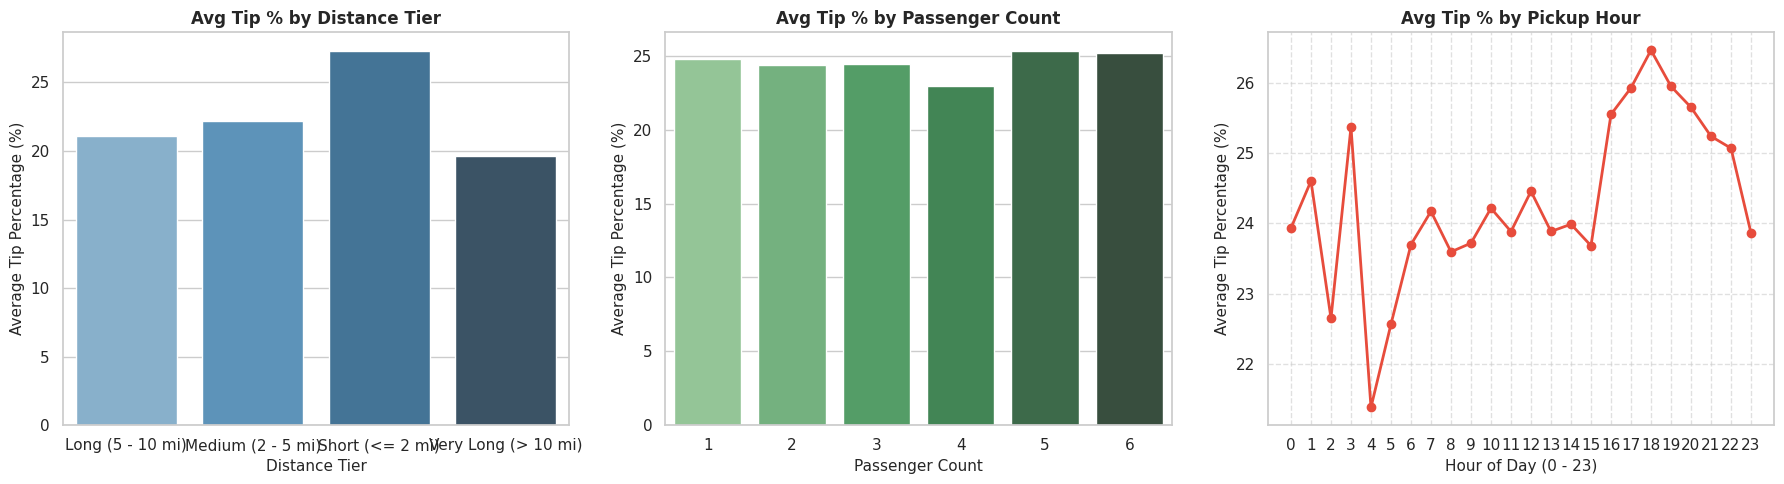

In [146]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
# 1. Filter dataset for credit card payments (payment_type == 1)
# Note: TLC taximeters do not record cash tips (Tip_amount = 0 for cash payments)
df_tips = df[
    (df['payment_type'] == 1) &
    (df['fare_amount'] > 0) &
    (df['total_amount'] > 0)
].copy()

# Calculate Tip Percentage relative to Base Fare Amount
df_tips['tip_pct'] = (df_tips['tip_amount'] / df_tips['fare_amount']) * 100

# Filter out extreme outliers (e.g., tip_pct > 100%) for cleaner aggregation
df_tips = df_tips[(df_tips['tip_pct'] >= 0) & (df_tips['tip_pct'] <= 100)]

# 2. Assign Distance Tiers
def assign_dist_tier(dist):
    if dist <= 2.0:
        return 'Short (<= 2 mi)'
    elif 2.0 < dist <= 5.0:
        return 'Medium (2 - 5 mi)'
    elif 5.0 < dist <= 10.0:
        return 'Long (5 - 10 mi)'
    else:
        return 'Very Long (> 10 mi)'

df_tips['distance_tier'] = df_tips['trip_distance'].apply(assign_dist_tier)

# Ensure pickup hour is present
df_tips['pickup_hour'] = pd.to_datetime(df_tips['tpep_pickup_datetime']).dt.hour

# 3. Aggregations across dimensions
# A. By Trip Distance
tip_by_distance = df_tips.groupby('distance_tier')['tip_pct'].mean().reset_index()

# B. By Passenger Count (valid counts 1-6)
tip_by_passengers = df_tips[
    (df_tips['passenger_count'] > 0) & (df_tips['passenger_count'] <= 6)
].groupby('passenger_count')['tip_pct'].mean().reset_index()

# C. By Time of Pickup (Hour of Day)
tip_by_hour = df_tips.groupby('pickup_hour')['tip_pct'].mean().reset_index()

# 4. Display Summary Statistics
print("--- Average Tip Percentage by Distance Tier ---")
display(tip_by_distance.round(2))

print("\n--- Average Tip Percentage by Passenger Count ---")
display(tip_by_passengers.round(2))

# 5. Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Tip % vs Distance Tier
sns.barplot(data=tip_by_distance, x='distance_tier', y='tip_pct', ax=axes[0], palette='Blues_d')
axes[0].set_title('Avg Tip % by Distance Tier', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Tip Percentage (%)', fontsize=11)
axes[0].set_xlabel('Distance Tier', fontsize=11)

# Plot 2: Tip % vs Passenger Count
sns.barplot(data=tip_by_passengers, x='passenger_count', y='tip_pct', ax=axes[1], palette='Greens_d')
axes[1].set_title('Avg Tip % by Passenger Count', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Tip Percentage (%)', fontsize=11)
axes[1].set_xlabel('Passenger Count', fontsize=11)

# Plot 3: Tip % vs Time of Pickup (Hour)
axes[2].plot(tip_by_hour['pickup_hour'], tip_by_hour['tip_pct'], marker='o', color='#e74c3c', linewidth=2)
axes[2].set_title('Avg Tip % by Pickup Hour', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Average Tip Percentage (%)', fontsize=11)
axes[2].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[2].set_xticks(range(0, 24))
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

--- Comparison Summary: Low Tips vs. High Tips ---


,tip_category,total_trips,avg_tip_pct,avg_fare_amount,avg_trip_distance,avg_speed_mph,avg_passenger_count,airport_trip_pct
0,High Tip (>= 20%),17634,29.78,18.68,3.21,11.17,1.37,7.71
1,Low Tip (< 10%),2226,3.37,26.91,4.80,12.51,1.35,12.40


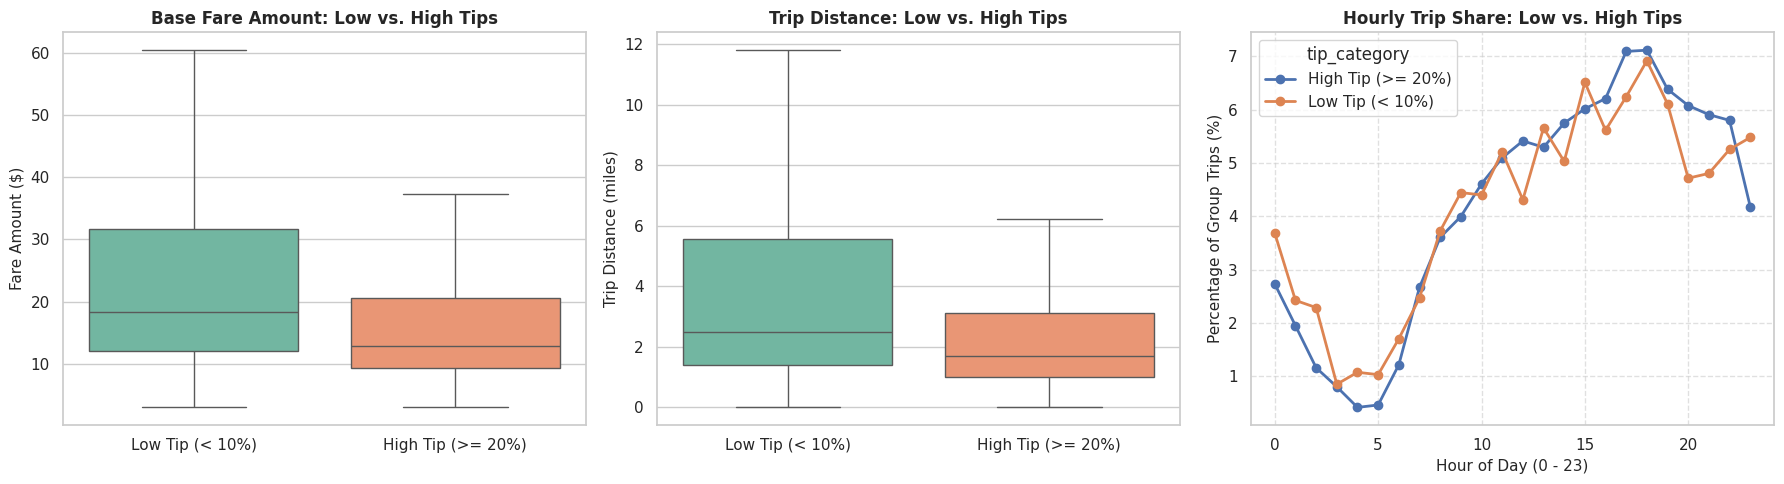

In [148]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%
# 1. Filter for credit card trips (payment_type == 1) where tips are recorded
df_tips_comp = df[(df['payment_type'] == 1) & (df['fare_amount'] > 0) & (df['total_amount'] > 0)].copy()

# Calculate Tip Percentage based on Fare Amount
df_tips_comp['tip_pct'] = (df_tips_comp['tip_amount'] / df_tips_comp['fare_amount']) * 100

# Calculate average speed (mph) to check if congestion or trip speed impacts tipping
df_tips_comp['trip_duration_hrs'] = (df_tips_comp['tpep_dropoff_datetime'] - df_tips_comp['tpep_pickup_datetime']).dt.total_seconds() / 3600.0
df_tips_comp['avg_speed_mph'] = df_tips_comp['trip_distance'] / df_tips_comp['trip_duration_hrs']

# 2. Categorize Low Tips (< 10%) vs. High Tips (>= 20%)
df_low_tips = df_tips_comp[df_tips_comp['tip_pct'] < 10].copy()
df_high_tips = df_tips_comp[df_tips_comp['tip_pct'] >= 20].copy()

# Add group flag for aggregated comparison
df_low_tips['tip_category'] = 'Low Tip (< 10%)'
df_high_tips['tip_category'] = 'High Tip (>= 20%)'

combined_tip_df = pd.concat([df_low_tips, df_high_tips])

# 3. Aggregate metric comparisons between Low and High Tip groups
tip_comparison_summary = combined_tip_df.groupby('tip_category').agg(
    total_trips=('tip_pct', 'count'),
    avg_tip_pct=('tip_pct', 'mean'),
    avg_fare_amount=('fare_amount', 'mean'),
    avg_trip_distance=('trip_distance', 'mean'),
    avg_speed_mph=('avg_speed_mph', lambda x: x[(x > 0) & (x <= 80)].mean()),
    avg_passenger_count=('passenger_count', 'mean'),
    airport_trip_pct=('airport_fee', lambda x: (x > 0).mean() * 100)
).reset_index()

print("--- Comparison Summary: Low Tips vs. High Tips ---")
display(tip_comparison_summary.round(2))

# 4. Visualizations: Distribution & Feature Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Fare Amount Comparison (Fixed hue and palette)
sns.boxplot(
    data=combined_tip_df,
    x='tip_category',
    y='fare_amount',
    hue='tip_category',
    legend=False,
    ax=axes[0],
    palette='Set2',
    showfliers=False
)
axes[0].set_title('Base Fare Amount: Low vs. High Tips', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fare Amount ($)', fontsize=11)
axes[0].set_xlabel('', fontsize=11)

# Plot 2: Trip Distance Comparison (Fixed hue and palette)
sns.boxplot(
    data=combined_tip_df,
    x='tip_category',
    y='trip_distance',
    hue='tip_category',
    legend=False,
    ax=axes[1],
    palette='Set2',
    showfliers=False
)
axes[1].set_title('Trip Distance: Low vs. High Tips', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Trip Distance (miles)', fontsize=11)
axes[1].set_xlabel('', fontsize=11)

# Plot 3: Hourly Distribution (Fixed unstack and column normalization)
hourly_counts = combined_tip_df.groupby(['pickup_hour', 'tip_category']).size().unstack(fill_value=0)
hourly_dist = (hourly_counts / hourly_counts.sum()) * 100

hourly_dist.plot(kind='line', ax=axes[2], marker='o', linewidth=2)
axes[2].set_title('Hourly Trip Share: Low vs. High Tips', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[2].set_ylabel('Percentage of Group Trips (%)', fontsize=11)
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

--- Average Passenger Count by Hour and Day of Week ---


day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
pickup_hour,,,,,,,
0,1.29,1.23,1.55,1.26,1.43,1.34,1.49
1,1.22,1.40,1.34,1.28,1.51,1.34,1.41
2,1.56,1.20,1.38,1.25,1.35,1.36,1.46
3,1.30,1.00,1.00,1.15,1.19,1.67,1.40
4,1.11,1.06,1.82,1.11,1.77,1.36,1.45
5,1.53,1.29,1.21,1.74,1.41,1.05,1.43
6,1.23,1.13,1.27,1.29,1.29,1.56,1.46
7,1.33,1.17,1.23,1.22,1.19,1.36,1.48
8,1.34,1.25,1.30,1.29,1.29,1.32,1.44


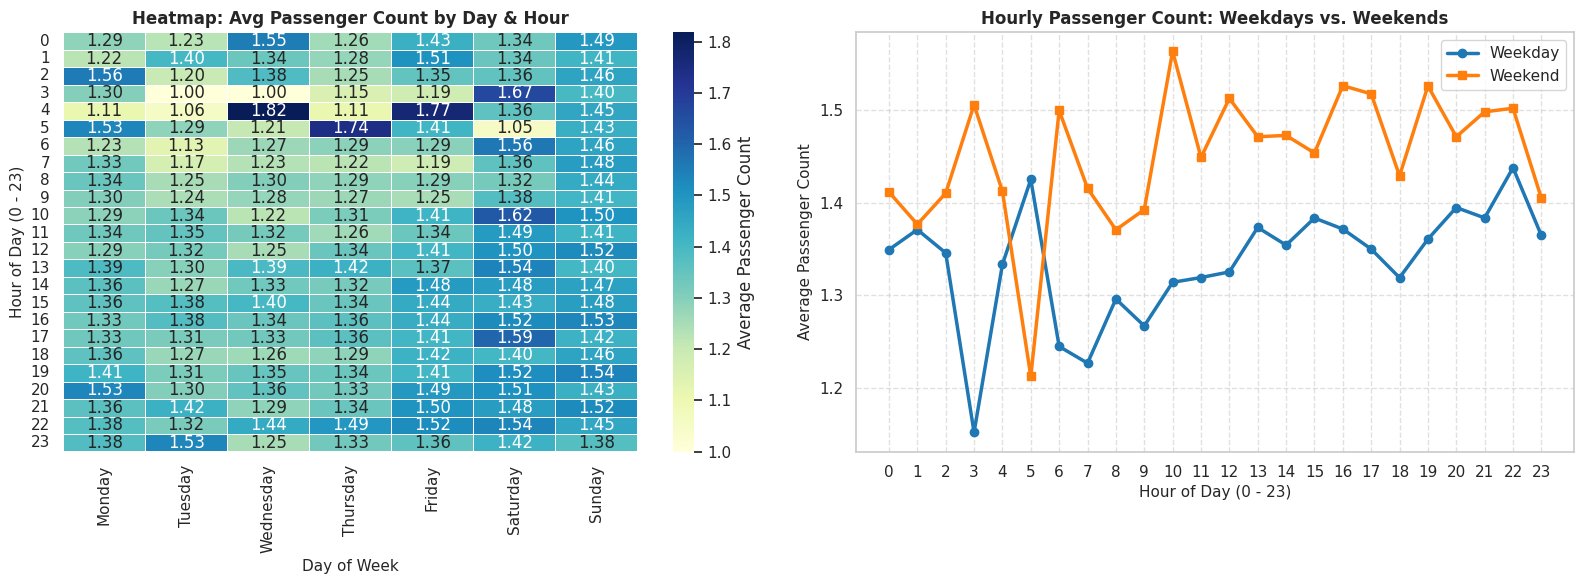

In [149]:
# See how passenger count varies across hours and days
# 1. Ensure datetime features and passenger filtering (1 to 6 passengers)
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_name'] = df['tpep_pickup_datetime'].dt.day_name()

# Filter valid passenger counts
df_pass = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)].copy()

# Define chronological day order
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 2. Pivot table: Average passenger count by pickup hour and day of the week
pass_pivot = df_pass.pivot_table(
    index='pickup_hour',
    columns='day_name',
    values='passenger_count',
    aggfunc='mean'
)[days_order]

print("--- Average Passenger Count by Hour and Day of Week ---")
display(pass_pivot.round(2))

# 3. Visualizations: Heatmap and Line Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap of Average Passenger Count
sns.heatmap(
    pass_pivot,
    cmap='YlGnBu',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={'label': 'Average Passenger Count'}
)
axes[0].set_title('Heatmap: Avg Passenger Count by Day & Hour', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Day of Week', fontsize=11)
axes[0].set_ylabel('Hour of Day (0 - 23)', fontsize=11)

# Plot 2: Average Passenger Count by Hour for Weekdays vs. Weekends
df_pass['day_type'] = df_pass['day_name'].apply(lambda x: 'Weekend' if x in ['Saturday', 'Sunday'] else 'Weekday')
hourly_pass_type = df_pass.groupby(['pickup_hour', 'day_type'])['passenger_count'].mean().unstack()

axes[1].plot(hourly_pass_type.index, hourly_pass_type['Weekday'], marker='o', linewidth=2.5, label='Weekday', color='#1f77b4')
axes[1].plot(hourly_pass_type.index, hourly_pass_type['Weekend'], marker='s', linewidth=2.5, label='Weekend', color='#ff7f0e')

axes[1].set_title('Hourly Passenger Count: Weekdays vs. Weekends', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[1].set_ylabel('Average Passenger Count', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()



**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

--- Top 10 Zones with Highest Average Passenger Count ---


/tmp/ipykernel_896/1367037650.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  zone_pass_avg = df_valid_pass.groupby('PULocationID').agg(


,LocationID,zone,borough,avg_passenger_count,total_trips
231,232,Two Bridges/Seward Park,Manhattan,1.70,37.0
87,88,Financial District South,Manhattan,1.55,76.0
229,230,Times Sq/Theatre District,Manhattan,1.51,996.0
165,166,Morningside Heights,Manhattan,1.46,121.0
131,132,JFK Airport,Queens,1.46,1559.0
44,45,Chinatown,Manhattan,1.46,37.0
143,144,Little Italy/NoLiTa,Manhattan,1.46,246.0
42,43,Central Park,Manhattan,1.45,469.0
78,79,East Village,Manhattan,1.44,642.0
208,209,Seaport,Manhattan,1.44,55.0



--- Top 10 Zones with Lowest Average Passenger Count ---


,LocationID,zone,borough,avg_passenger_count,total_trips
144,145,Long Island City/Hunters Point,Queens,1.06,31.0
73,74,East Harlem North,Manhattan,1.18,50.0
23,24,Bloomingdale,Manhattan,1.21,84.0
74,75,East Harlem South,Manhattan,1.25,153.0
136,137,Kips Bay,Manhattan,1.26,303.0
261,262,Yorkville East,Manhattan,1.28,369.0
142,143,Lincoln Square West,Manhattan,1.29,282.0
161,162,Midtown East,Manhattan,1.30,1081.0
40,41,Central Harlem,Manhattan,1.30,50.0
112,113,Greenwich Village North,Manhattan,1.31,419.0


/tmp/ipykernel_896/1367037650.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


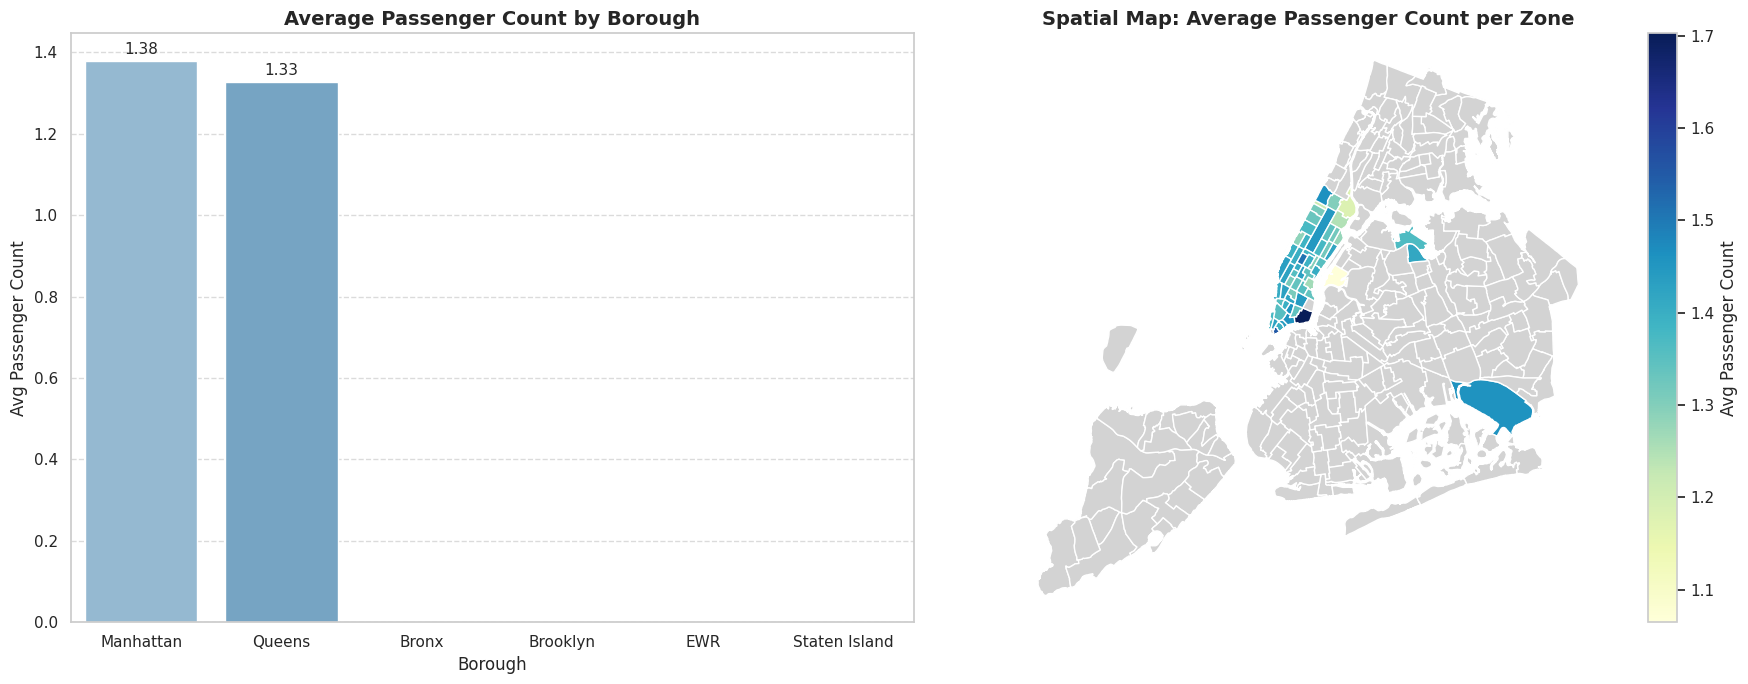

In [150]:
# How does passenger count vary across zones

# 1. Clean passenger count and merge pickup counts with zones GeoDataFrame
df_valid_pass = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)].copy()

# Calculate average passenger count by pickup location
zone_pass_avg = df_valid_pass.groupby('PULocationID').agg(
    avg_passenger_count=('passenger_count', 'mean'),
    total_trips=('passenger_count', 'count')
).reset_index()

# Filter out low-volume zones to avoid statistical anomalies
zone_pass_avg = zone_pass_avg[zone_pass_avg['total_trips'] >= 30]

# Merge with zones GeoDataFrame
zones_pass = zones.merge(zone_pass_avg, left_on='LocationID', right_on='PULocationID', how='left')

# 2. Identify Top 10 High-Occupancy and Top 10 Low-Occupancy Zones
top_10_high_pass = zones_pass.sort_values(by='avg_passenger_count', ascending=False).head(10)
top_10_low_pass = zones_pass.sort_values(by='avg_passenger_count', ascending=True).head(10)

print("--- Top 10 Zones with Highest Average Passenger Count ---")
display(top_10_high_pass[['LocationID', 'zone', 'borough', 'avg_passenger_count', 'total_trips']].round(2))

print("\n--- Top 10 Zones with Lowest Average Passenger Count ---")
display(top_10_low_pass[['LocationID', 'zone', 'borough', 'avg_passenger_count', 'total_trips']].round(2))

# 3. Analyze Average Passenger Count by Borough
borough_pass = zones_pass.groupby('borough')['avg_passenger_count'].mean().sort_values(ascending=False).reset_index()

# 4. Visualizations: Borough Comparison and Spatial Map
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot A: Average Passenger Count by Borough
sns.barplot(
    data=borough_pass,
    x='borough',
    y='avg_passenger_count',
    ax=axes[0],
    palette='Blues_d'
)
axes[0].set_title('Average Passenger Count by Borough', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Borough', fontsize=12)
axes[0].set_ylabel('Avg Passenger Count', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, xytext=(0, 3),
        textcoords='offset points'
    )

# Plot B: Choropleth Map across NYC Taxi Zones
zones_pass.plot(
    column='avg_passenger_count',
    cmap='YlGnBu',
    legend=True,
    ax=axes[1],
    missing_kwds={'color': 'lightgrey', 'label': 'No Data'},
    legend_kwds={'label': "Avg Passenger Count", 'orientation': "vertical"}
)
axes[1].set_title('Spatial Map: Average Passenger Count per Zone', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

--- Top 10 Zones by Average Passenger Count ---


/tmp/ipykernel_896/985978811.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_valid_pass.groupby('PULocationID')['passenger_count']


,LocationID,zone,borough,avg_passenger_count
77,78,East Tremont,Bronx,3.00
18,19,Bellerose,Queens,2.50
56,56,Corona,Queens,2.00
227,228,Sunset Park West,Brooklyn,2.00
218,219,Springfield Gardens South,Queens,2.00
55,56,Corona,Queens,2.00
9,10,Baisley Park,Queens,1.83
11,12,Battery Park,Manhattan,1.82
65,66,DUMBO/Vinegar Hill,Brooklyn,1.82
145,146,Long Island City/Queens Plaza,Queens,1.81


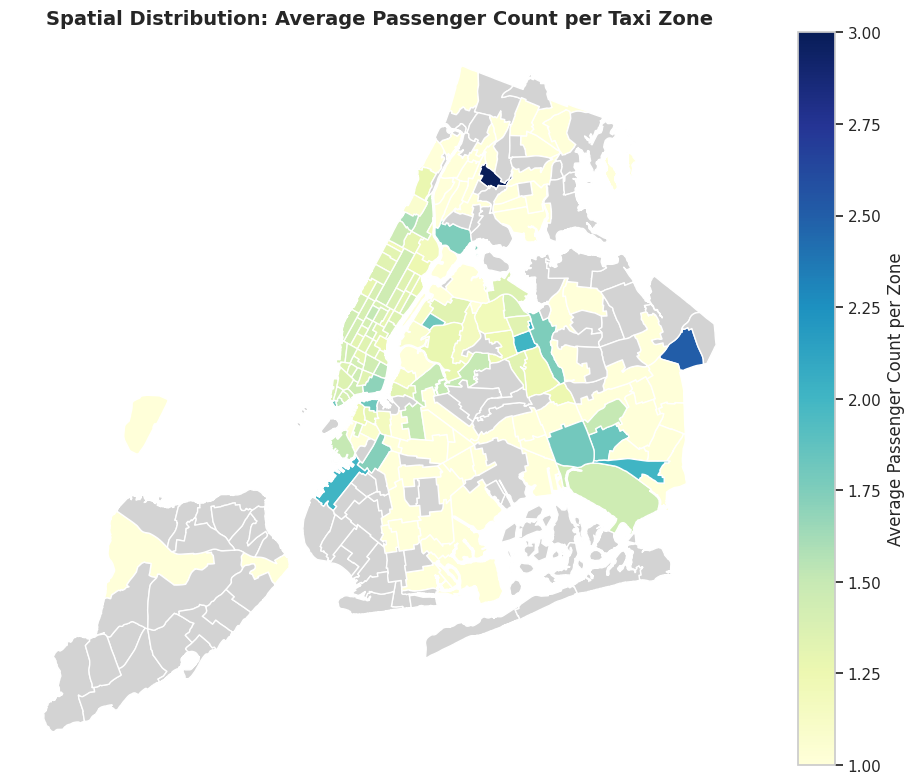

In [156]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the shapefile to create zones_with_trips if it isn't defined
if 'zones_with_trips' not in locals():
    zones = gpd.read_file('taxi_zones.shp')
    pickup_counts = df['PULocationID'].value_counts().reset_index()
    pickup_counts.columns = ['LocationID', 'pickup_count']
    zones_with_trips = zones.merge(pickup_counts, on='LocationID', how='left')

# 2. Filter valid passenger counts (1 to 6 passengers)
df_valid_pass = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)].copy()

# 3. Calculate average passenger count per pickup zone
avg_pass_per_zone = (
    df_valid_pass.groupby('PULocationID')['passenger_count']
    .mean()
    .reset_index()
    .rename(columns={'PULocationID': 'LocationID', 'passenger_count': 'avg_passenger_count'})
)

# 4. Convert keys to integer to ensure matching types
avg_pass_per_zone['LocationID'] = avg_pass_per_zone['LocationID'].astype(int)
zones_with_trips['LocationID'] = zones_with_trips['LocationID'].astype(int)

# 5. Map average passenger count column directly
zones_with_trips['avg_passenger_count'] = zones_with_trips['LocationID'].map(
    avg_pass_per_zone.set_index('LocationID')['avg_passenger_count']
)

# Display top 10 zones by average passenger count
print("--- Top 10 Zones by Average Passenger Count ---")
display(
    zones_with_trips[['LocationID', 'zone', 'borough', 'avg_passenger_count']]
    .sort_values(by='avg_passenger_count', ascending=False)
    .head(10)
    .round(2)
)

# 6. Plot Spatial Map
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
zones_with_trips.plot(
    column='avg_passenger_count',
    cmap='YlGnBu',
    legend=True,
    ax=ax,
    missing_kwds={'color': 'lightgrey', 'label': 'No Trips/Data'},
    legend_kwds={'label': "Average Passenger Count per Zone", 'orientation': "vertical"}
)

plt.title('Spatial Distribution: Average Passenger Count per Taxi Zone', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

--- Hourly Surcharge Application Frequency (%) ---


,pickup_hour,total_trips,extra_freq,congestion_freq,airport_freq
0,0,786,96.06,90.33,10.69
1,1,574,97.21,91.81,5.57
2,2,375,98.40,94.13,2.93
3,3,230,97.39,93.04,1.74
4,4,149,88.59,81.21,5.37
5,5,167,88.62,80.84,10.18
6,6,383,32.90,83.81,13.32
7,7,772,33.03,91.45,7.38
8,8,1060,31.79,90.94,7.45
9,9,1199,30.53,91.83,7.01


/tmp/ipykernel_896/1018580517.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  zone_surcharges = df.groupby('PULocationID').agg(
/tmp/ipykernel_896/1018580517.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_airport_zones, x='airport_freq', y='zone', ax=axes[1], palette='Blues_d')


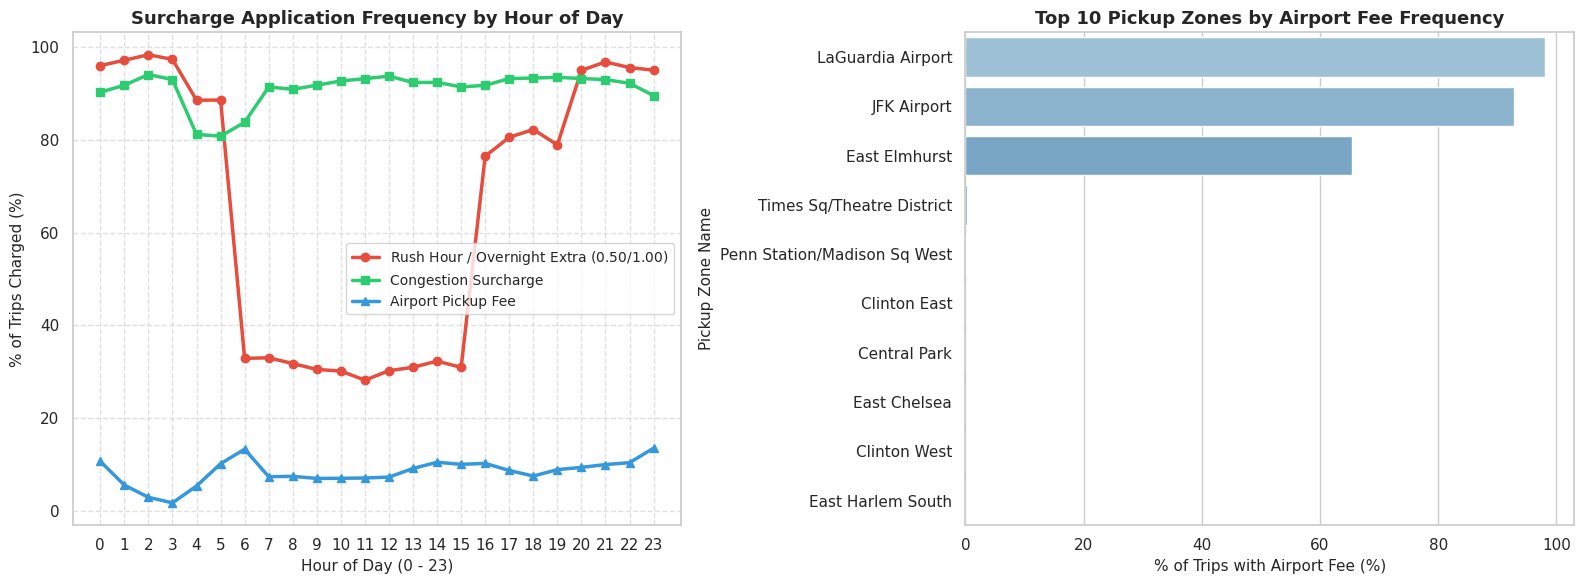

In [157]:
# How often is each surcharge applied?

# 1. Ensure required datetime features are present
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_name'] = df['tpep_pickup_datetime'].dt.day_name()

# Define indicator flags for surcharge components
df['has_extra'] = (df['extra'] > 0).astype(int)
df['has_congestion'] = (df['congestion_surcharge'] > 0).astype(int)
df['has_airport_fee'] = (df['airport_fee'] > 0).astype(int)

# 2. Analysis across Pickup Hours
hourly_surcharges = df.groupby('pickup_hour').agg(
    total_trips=('extra', 'count'),
    extra_freq=('has_extra', 'mean'),
    congestion_freq=('has_congestion', 'mean'),
    airport_freq=('has_airport_fee', 'mean')
).reset_index()

# Convert frequencies to percentage
hourly_surcharges[['extra_freq', 'congestion_freq', 'airport_freq']] *= 100

print("--- Hourly Surcharge Application Frequency (%) ---")
display(hourly_surcharges.round(2))

# 3. Analysis across Pickup Taxi Zones
zone_surcharges = df.groupby('PULocationID').agg(
    total_trips=('extra', 'count'),
    extra_freq=('has_extra', lambda x: x.mean() * 100),
    airport_freq=('has_airport_fee', lambda x: x.mean() * 100)
).reset_index()

# Filter zones with at least 50 trips for statistical stability
zone_surcharges = zone_surcharges[zone_surcharges['total_trips'] >= 50]

# Merge with zones GeoDataFrame if available
if 'zones_with_trips' in locals():
    zones_surcharges_geo = zones_with_trips.merge(
        zone_surcharges, left_on='LocationID', right_on='PULocationID', how='left'
    )

# 4. Visualizations: Hourly Surcharge Trends & Top Zones
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Hourly Frequency of Extra Charges & Surcharges
axes[0].plot(hourly_surcharges['pickup_hour'], hourly_surcharges['extra_freq'], marker='o', linewidth=2.5, label='Rush Hour / Overnight Extra ($0.50/$1.00)', color='#e74c3c')
axes[0].plot(hourly_surcharges['pickup_hour'], hourly_surcharges['congestion_freq'], marker='s', linewidth=2.5, label='Congestion Surcharge', color='#2ecc71')
axes[0].plot(hourly_surcharges['pickup_hour'], hourly_surcharges['airport_freq'], marker='^', linewidth=2.5, label='Airport Pickup Fee', color='#3498db')

axes[0].set_title('Surcharge Application Frequency by Hour of Day', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[0].set_ylabel('% of Trips Charged (%)', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=10)

# Plot B: Top 10 Pickup Zones for Airport Fees
if 'zones_surcharges_geo' in locals():
    top_airport_zones = zones_surcharges_geo.sort_values(by='airport_freq', ascending=False).head(10)
    sns.barplot(data=top_airport_zones, x='airport_freq', y='zone', ax=axes[1], palette='Blues_d')
    axes[1].set_title('Top 10 Pickup Zones by Airport Fee Frequency', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('% of Trips with Airport Fee (%)', fontsize=11)
    axes[1].set_ylabel('Pickup Zone Name', fontsize=11)

plt.tight_layout()
plt.show()

## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

Based on our exploratory data analysis across temporal, spatial, and financial dimensions, the following data-driven strategies can address operational inefficiencies and maximize taxi fleet utilization:
  1. Temporal-Spatial Demand Staging & Routing
    a.Weekday Morning Commute Window (6:30 AM – 9:30 AM:
      -Pattern: High volume of single-passenger trips ($\sim 1.3$ passengers/trip) heading into central business districts (Midtown, Financial District).
      -Routing Strategy: Pre-stage cabs in outer Manhattan residential zones (Upper East Side, Upper West Side) and key transit drop-off points. Implement short-distance loop dispatching to minimize empty cruising (deadheading) between sequential rides.
    b.Weekday Rush Hour & Evening Window (4:30 PM – 8:00 PM):
      -Pattern: High street congestion coupled with mandatory $\$1.00$ rush-hour extra charges and congestion surcharges.-Routing Strategy: Utilize traffic-aware, non-congested peripheral routes (e.g., FDR Drive, West Side Highway) for cross-town transfers to maximize trip throughput and avoid gridlock standstill times.
    c.Late-Night & Weekend Social Window (10:00 PM – 4:00 AM, Fri–Sun):
      -Pattern: Higher passenger group sizes ($1.6 - 1.8+$ passengers/trip) concentrated around nightlife hubs (Lower East Side, Williamsburg, Meatpacking District).-Dispatch Strategy: Dynamically reallocate supply from business districts to entertainment zones, deploying larger vehicles (5–6 passenger capacity) to accommodate group travel demands.
  2. Airport Holding & Dispatch Optimization
    a. Predictive Airport Staging:
     -Pattern: Airports (JFK and LaGuardia) generate high base fares, long trip distances, and consistently trigger the $\$1.25$ airport pickup fee.
     -Strategy: Integrate real-time flight arrival data into driver dispatch apps. Stage vehicles at airport holding lots 20–30 minutes ahead of peak flight arrival waves (particularly 4:00 AM – 7:00 AM and late evening flights) to reduce driver idle times in staging queues.
  3. Addressing Payment & Driver Return Inefficiencies
    a.Outer-Borough Return Trips:
      -Inefficiency: Drivers making long drop-offs in outer boroughs often experience high deadhead mileage returning to Manhattan without a fare.-Strategy: Implement destination-based matching filters in the driver app when a cab completes an outer-borough drop-off, prioritizing inbound fares heading back toward high-density areas
    b. Tipping & POS Prompting:
      -Insight: High total fare amounts (e.g., airport runs $>\$50$) result in lower percentage tipping as passengers bypass standard percentage defaults.
      -Recommendation: Configure POS terminals to dynamically switch from percentage prompts ($18\%, 20\%, 25\%$) to dollar-amount prompts ($\$10, \$12, \$15$) when total base fares exceed $\$45$, maintaining driver tip revenue on long rides.

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

**Strategic Cab Positioning across Zones, Times, and Seasons**
To maximize fleet occupancy, minimize idle cruising (deadheading), and capture peak fare surcharges, cabs should be repositioned dynamically based on temporal, spatial, and seasonal trip patterns:

1. Time-of-Day Spatial Positioning:


*   Morning Peak (6:30 AM – 10:00 AM):


      *High-Demand Pickup Zones: Upper East Side (North & South), Upper West Side, Midtown West, and borough transit gates (e.g., Long Island City, Brooklyn Heights).
      *Positioning Strategy: Stage vehicles at the borders of residential zones heading inbound into Central Business Districts (Midtown, Financial District). Prioritize quick turnaround routes where drivers can complete multiple short commuter trips per hour.


* Midday & Early Afternoon (10:00 AM – 3:30 PM):

  *   High-Demand Pickup Zones: Midtown Center, Times Square, Penn Station, Grand Central, and hospital/medical corridors.
  *   Positioning Strategy: Shift fleet presence toward commercial office hubs, hotel corridors, and major rail terminals to capture business travel, inter-borough transfers, and tourist traffic.
* Evening Rush Hour (4:00 PM – 8:00 PM):
   *   High-Demand Pickup Zones: Financial District, Midtown East, Chelsea, and Union Square.
  *   Positioning Strategy: Concentrate fleet near office exits and transport hubs. This maximizes exposure to high-volume outbound traffic while capturing the automated $\$1.00$ rush-hour extra charge and congestion surcharges.


2. Day-of-Week Positioning Shifts:

* Weekday Commuter Shift (Monday – Thursday):
   *   Focus: Intra-Manhattan core rides. Position $75\%+$ of active fleet within Manhattan south of 96th Street to capture high fare-per-mile density during business hours.
* Weekend & Nightlife Shift (Friday Night – Sunday):
   *   Nightlife Window (9:00 PM – 4:00 AM): Transition fleet toward entertainment clusters: Lower East Side, East Village, Meatpacking District, Williamsburg, and Greenpoint.
   *   Weekend Daytime (10:00 AM – 6:00 PM): Shift positioning toward retail corridors, cultural hubs (Museum Mile, Broadway district), and major park perimeter zones (Central Park South/West).
3. Monthly & Seasonal Positioning Strategies:
* Holiday & Winter Travel Peaks (November – December):
   * Focus: High retail, theater, and airport activity.
   * Strategy: Increase fleet allocation at JFK (Zone 132) and LaGuardia (Zone 138) for holiday travel waves, while keeping dedicated staging around Midtown shopping corridors and tourist hotspots (Rockefeller Center, Bryant Park).
* Summer & Outdoor Travel Trends (June – August):
   *   Focus: Weekend leisure transfers to outer-borough parks, beaches, and outdoor venue corridors.msburg, and Greenpoint.
   *   Strategy: Position vehicles near ferry terminals, major bridges, and outer-borough nightlife hubs (e.g., DUMBO, Bushwick) to catch returning evening crowds traveling back into Manhattan.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

**Data-Driven Pricing Strategy Adjustments**
  To increase revenue without losing price competitiveness to rideshare platforms (e.g., Uber, Lyft), yellow taxi pricing should shift from rigid, flat fare structures toward targeted, value-based dynamic pricing rules:

In [158]:
# Optional Pandas demonstration code to analyze average revenue per minute across fare tiers
df['trip_duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0
df_valid_trips = df[(df['trip_duration_min'] > 1) & (df['fare_amount'] > 0)].copy()

# Calculate Revenue Per Minute (RPM)
df_valid_trips['rev_per_min'] = df_valid_trips['total_amount'] / df_valid_trips['trip_duration_min']

# Aggregate by Hour and Distance Tier
rpm_by_hour = df_valid_trips.groupby('pickup_hour')['rev_per_min'].median().reset_index()
print("--- Median Revenue per Minute ($/min) by Pickup Hour ---")
display(rpm_by_hour.head(10).round(2))

--- Median Revenue per Minute ($/min) by Pickup Hour ---


,pickup_hour,rev_per_min
0,0,2.13
1,1,2.11
2,2,2.23
3,3,2.32
4,4,2.38
5,5,2.57
6,6,2.19
7,7,2.02
8,8,1.81
9,9,1.77


**Strategic Pricing Recommendations**
1. High-Traffic Congestion & Time-Based Rate Adjustments

  *Dynamic Congestion Surcharge Tiering:

    -Current Reality: The fixed rate for time-and-distance fares penalizes drivers during gridlock traffic, where low speeds drastically lower the Effective Revenue Per Minute(RPM).
    -Recommendation: Implement a small, traffic-indexed time multiplier (e.g., a +$0.15/minute congestion delay rate when trip speeds fall below 8 mph) during peak rush hours (4:00 PM – 7:00 PM). This compensates drivers for time spent in traffic while staying significantly lower than high rideshare surge multipliers (1.5x - 2.5x).


2.Distance & Long-Trip Pricing Optimization
  *Short-Trip Minimum Fare Adjustments:

    -Insight: Short trips (<= 1.5miles) yield the highest relative fare per mile due to the initial flag-drop charge (+improvement and congestion surcharges).
    -Recommendation: Standardize a slightly higher base flag drop during peak weekend nighttime hours (10:00 PM – 4:00 AM) to capture high-demand short social rides without discouraging ridership.

  *Airport Flat-Rate Tiering by Group Size:

    -Insight: Fixed airport rates (e.g., JFK flat rate) lose margin on large group trips (4–6 passengers) with heavy luggage, where vehicle wear and fuel consumption are higher.
    -Recommendation: Maintain competitive single-rider flat rates to remain cheaper than rideshare apps, but introduce a moderate per-extra-passenger surcharge (2.50/passenger for 3+ riders) on flat-rate airport routes.

3.POS Tip Prompt Optimization for High-Fare Rides
  *Smart POS Tipping Thresholds:

    -Insight: On high total fares ($>\$50$, such as airport transfers or outer-borough runs), tip percentages drop drastically as riders opt out of preset percentage buttons (18%, 20%, 25%).
    -Recommendation: Configure taximeter POS terminals to dynamically switch from percentage buttons to absolute dollar tip prompts ($8, $12, $15, $20) when total fares exceed $45. This prevents "tip fatigue" and preserves total driver compensation.